<a href="https://colab.research.google.com/github/NancyWangareh/ReCover/blob/main/ReCover_Trader_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ReCover Trader Dataset — Exploratory Data Analysis

This notebook analyzes trader risks, insurance preferences, payment preferences, insurance history, digital access, trader segments, and stated willingness to pay.

**Important:** Results describe only the records in this dataset. Confirm whether the data is real survey data, synthetic data, or a mixture before making claims about Kenyan mitumba traders generally. This notebook does not make insurance-product recommendations.

## 0. Setup and load the dataset

In [ ]:
%pip install pandas numpy matplotlib seaborn scipy scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme()  # Uses a readable default theme; no custom color palette is imposed.
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)




In [ ]:
#connect with drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
DATA_PATH = Path("/content/drive/MyDrive/ReCover/Recommendation_system/Data/Traders_dataset.csv")
df = pd.read_csv(DATA_PATH)

print("Rows, columns:", df.shape)
display(df.tail())
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1),
    "unique_values": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False))

Rows, columns: (290, 50)


,trader_id,age,gender,education_level,language_pref,dependents,is_main_breadwinner,county,market_name,role,stall_type,mitumba_category,years_in_trade,num_employees,monthly_income_kes,income_variability,income_receipt_pattern,preferred_premium_frequency,restock_cycle_days,owns_stock,stock_value_kes,has_electrical_connection,market_association_member,has_kra_pin,uses_mpesa,mpesa_monthly_volume_kes,smartphone_owner,whatsapp_user,preferred_channel,wants_cover_fire,wants_cover_theft,wants_cover_health,wants_cover_weather_flood,wants_cover_accident,primary_risk_concern,total_loss_24m_kes,primary_coping_mechanism,sacco_member,has_outstanding_loan,sha_status,prior_microinsurance,lapse_reason,insurance_awareness_score,trust_in_insurers_score,income_tier,wtp_monthly_kes,wtp_weekly_kes,wtp_per_payment_kes,record_type,location_role
285,T0753,32,female,primary,english,7,True,Nairobi,Toi Market,owner,permanent_shop,childrens_wear,11,1,113500,low,daily,pay_at_restock,14,True,337000,True,False,False,True,481500,False,False,ussd,False,False,True,False,False,health,23000,personal_savings,False,False,not_registered,lapsed,slow_claims,3,2,high,1163,269,543,Synthetic observation — not an actual intervie...,Primary field research market context
286,T0303,32,female,tertiary_vocational,sheng,0,True,Nairobi,Kamukunji Market,owner,permanent_shop,womens_wear,2,3,115500,medium,daily,weekly,14,True,356000,True,False,False,True,584000,True,True,whatsapp,True,False,False,False,False,fire,0,sacco_or_loan,True,True,registered_not_paying,never,not_applicable,4,3,high,696,161,161,Synthetic observation — not an actual intervie...,Synthetic expansion scenario — not field-resea...
287,T0340,32,male,secondary,english,1,True,Mombasa,Kongowea Market,owner,permanent_shop,mixed_clothing,3,4,118500,medium,weekly,weekly,30,True,301000,True,False,False,True,794500,True,True,whatsapp,True,False,False,False,False,fire,0,none,True,False,not_registered,never,not_applicable,4,3,high,943,218,218,Synthetic observation — not an actual intervie...,Synthetic expansion scenario — not field-resea...
288,T0722,33,male,secondary,sheng,2,False,Nairobi,Toi Market,owner,permanent_shop,mixed_clothing,8,1,119000,low,daily,daily,30,True,263000,True,False,False,True,807000,True,False,either,False,True,False,False,False,theft,0,personal_savings,False,False,registered_not_paying,never,not_applicable,3,3,high,925,214,31,Synthetic observation — not an actual intervie...,Primary field research market context
289,T0742,30,male,secondary,swahili,3,True,Nairobi,Muthurwa Market,owner,permanent_shop,bedding_linen,10,2,120000,low,daily,daily,21,True,383000,True,False,False,True,790500,False,False,ussd,False,True,True,False,False,health,0,absorb_from_profits,False,False,registered_not_paying,never,not_applicable,3,5,high,884,204,29,Synthetic observation — not an actual intervie...,Synthetic expansion scenario — not field-resea...


,dtype,missing_count,missing_pct,unique_values
trader_id,object,0,0.0,290
age,int64,0,0.0,35
gender,object,0,0.0,2
education_level,object,0,0.0,3
language_pref,object,0,0.0,3
dependents,int64,0,0.0,8
is_main_breadwinner,bool,0,0.0,2
county,object,0,0.0,2
market_name,object,0,0.0,5
role,object,0,0.0,1


## 1. Data quality checks

In [ ]:
# 1A. Duplicate records and IDs
print("Duplicate full rows:", df.duplicated().sum())
if "trader_id" in df.columns:
    print("Duplicate trader IDs:", df["trader_id"].duplicated().sum())

# 1B. Review category values (helps catch spelling/case inconsistencies)
categorical_cols = df.select_dtypes(include=["object", "bool", "category"]).columns
for col in categorical_cols:
    print(f"\\n{col}:")
    display(df[col].value_counts(dropna=False).rename_axis(col).reset_index(name="count"))

# 1C. Numeric summaries and potential outliers
display(df.select_dtypes(include=np.number).describe().T)

# 1D. Basic consistency checks; investigate flagged records rather than deleting automatically.
checks = {}
if {"wtp_monthly_kes", "wtp_per_payment_kes"}.issubset(df.columns):
    checks["per_payment_gt_monthly_wtp"] = df["wtp_per_payment_kes"] > df["wtp_monthly_kes"]
if {"smartphone_owner", "whatsapp_user", "preferred_channel"}.issubset(df.columns):
    checks["no_smartphone_but_whatsapp_preferred"] = (
        (~df["smartphone_owner"].astype("boolean").fillna(False)) &
        (df["preferred_channel"].astype(str).str.lower() == "whatsapp")
    )
    checks["not_whatsapp_user_but_whatsapp_preferred"] = (
        (~df["whatsapp_user"].astype("boolean").fillna(False)) &
        (df["preferred_channel"].astype(str).str.lower() == "whatsapp")
    )

for label, mask in checks.items():
    print(label, ":", int(mask.fillna(False).sum()), "records")
    display(df.loc[mask.fillna(False)].head(10))

Duplicate full rows: 0
Duplicate trader IDs: 0
\ntrader_id:


,trader_id,count
0,T0109,1
1,T0925,1
2,T0366,1
3,T0322,1
4,T0069,1
...,...,...
285,T0753,1
286,T0303,1
287,T0340,1
288,T0722,1


\ngender:


,gender,count
0,female,156
1,male,134


\neducation_level:


,education_level,count
0,secondary,144
1,primary,87
2,tertiary_vocational,59


... (69 outputs left out)

no_smartphone_but_whatsapp_preferred : 0 records


,trader_id,age,gender,education_level,language_pref,dependents,is_main_breadwinner,county,market_name,role,stall_type,mitumba_category,years_in_trade,num_employees,monthly_income_kes,income_variability,income_receipt_pattern,preferred_premium_frequency,restock_cycle_days,owns_stock,stock_value_kes,has_electrical_connection,market_association_member,has_kra_pin,uses_mpesa,mpesa_monthly_volume_kes,smartphone_owner,whatsapp_user,preferred_channel,wants_cover_fire,wants_cover_theft,wants_cover_health,wants_cover_weather_flood,wants_cover_accident,primary_risk_concern,total_loss_24m_kes,primary_coping_mechanism,sacco_member,has_outstanding_loan,sha_status,prior_microinsurance,lapse_reason,insurance_awareness_score,trust_in_insurers_score,income_tier,wtp_monthly_kes,wtp_weekly_kes,wtp_per_payment_kes,record_type,location_role


not_whatsapp_user_but_whatsapp_preferred : 0 records


,trader_id,age,gender,education_level,language_pref,dependents,is_main_breadwinner,county,market_name,role,stall_type,mitumba_category,years_in_trade,num_employees,monthly_income_kes,income_variability,income_receipt_pattern,preferred_premium_frequency,restock_cycle_days,owns_stock,stock_value_kes,has_electrical_connection,market_association_member,has_kra_pin,uses_mpesa,mpesa_monthly_volume_kes,smartphone_owner,whatsapp_user,preferred_channel,wants_cover_fire,wants_cover_theft,wants_cover_health,wants_cover_weather_flood,wants_cover_accident,primary_risk_concern,total_loss_24m_kes,primary_coping_mechanism,sacco_member,has_outstanding_loan,sha_status,prior_microinsurance,lapse_reason,insurance_awareness_score,trust_in_insurers_score,income_tier,wtp_monthly_kes,wtp_weekly_kes,wtp_per_payment_kes,record_type,location_role


## 2. Risk profiling

### 2A. Primary risk concern

The bar chart shows the number of traders in each primary-risk category. These are counts in the dataset, not population estimates.

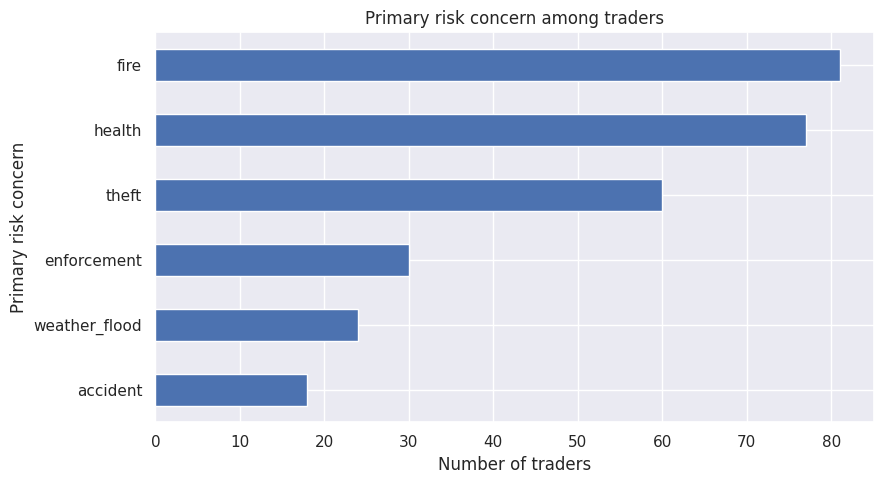

,traders,percent
primary_risk_concern,,
fire,81,27.9
health,77,26.6
theft,60,20.7
enforcement,30,10.3
weather_flood,24,8.3
accident,18,6.2


In [ ]:
risk_counts = df["primary_risk_concern"].fillna("missing").value_counts().sort_values(ascending=True)
ax = risk_counts.plot(kind="barh", figsize=(9, 5))
ax.set_title("Primary risk concern among traders")
ax.set_xlabel("Number of traders")
ax.set_ylabel("Primary risk concern")
plt.tight_layout()
plt.show()

risk_summary = risk_counts.rename("traders").to_frame()
risk_summary["percent"] = (risk_summary["traders"] / len(df) * 100).round(1)
display(risk_summary.sort_values("traders", ascending=False))

### 2B. Interest in different types of cover

,cover_type,interested_count,valid_responses,percent_of_valid
0,Fire,148,290,51.0
2,Health,148,290,51.0
1,Theft,130,290,44.8
4,Accident,79,290,27.2
3,Weather / flood,64,290,22.1


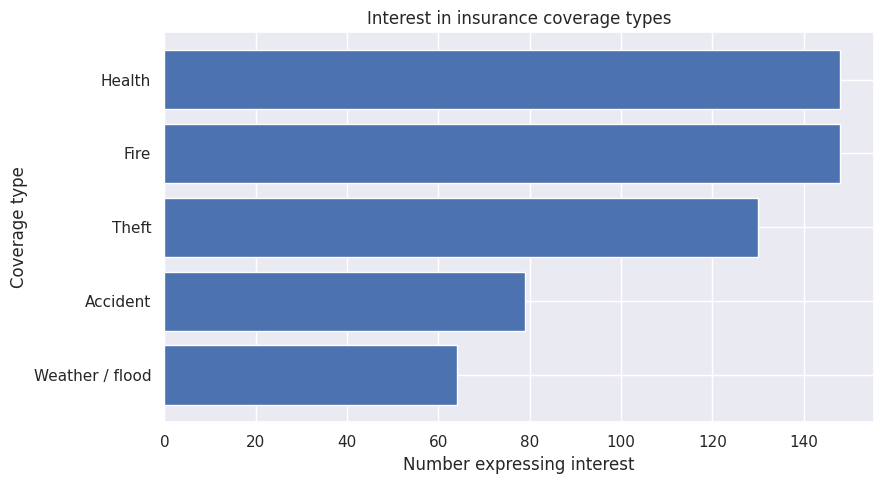

In [ ]:
cover_cols = [
    "wants_cover_fire", "wants_cover_theft", "wants_cover_health",
    "wants_cover_weather_flood", "wants_cover_accident"
]
cover_labels = {
    "wants_cover_fire": "Fire",
    "wants_cover_theft": "Theft",
    "wants_cover_health": "Health",
    "wants_cover_weather_flood": "Weather / flood",
    "wants_cover_accident": "Accident"
}
available_cover_cols = [c for c in cover_cols if c in df.columns]
cover_summary = pd.DataFrame({
    "cover_type": [cover_labels[c] for c in available_cover_cols],
    "interested_count": [df[c].eq(True).sum() for c in available_cover_cols],
    "valid_responses": [df[c].notna().sum() for c in available_cover_cols]
})
cover_summary["percent_of_valid"] = (
    cover_summary["interested_count"] / cover_summary["valid_responses"] * 100
).round(1)
display(cover_summary.sort_values("interested_count", ascending=False))

plot_data = cover_summary.sort_values("interested_count")
plt.figure(figsize=(9, 5))
plt.barh(plot_data["cover_type"], plot_data["interested_count"])
plt.title("Interest in insurance coverage types")
plt.xlabel("Number expressing interest")
plt.ylabel("Coverage type")
plt.tight_layout()
plt.show()

## 3. Income variability and premium-payment preferences

### 3A. Income variability × preferred payment frequency

A 100% stacked bar chart compares payment preferences *within* each income-variability group.

preferred_premium_frequency,daily,monthly,pay_at_restock,weekly
income_variability,,,,
high,31.6,14.0,15.8,38.6
low,19.5,24.4,22.0,34.1
medium,11.9,23.8,24.5,39.7


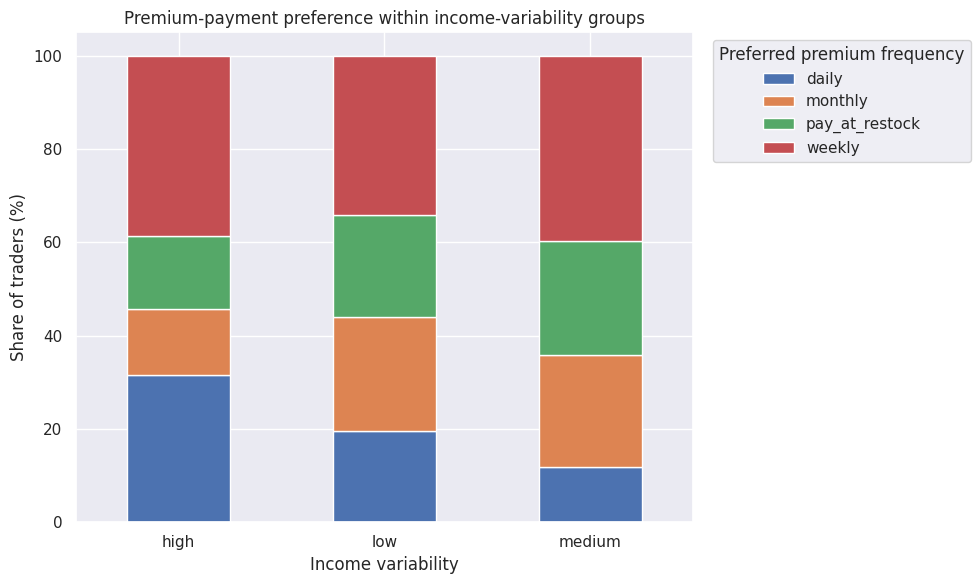

In [ ]:
payment_col = "preferred_premium_frequency"
variability_col = "income_variability"
ct = pd.crosstab(df[variability_col], df[payment_col], normalize="index") * 100
display(ct.round(1))

ax = ct.plot(kind="bar", stacked=True, figsize=(10, 6))
ax.set_title("Premium-payment preference within income-variability groups")
ax.set_xlabel("Income variability")
ax.set_ylabel("Share of traders (%)")
ax.legend(title="Preferred premium frequency", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 3B. Restocking cycle and amount willing to pay per payment

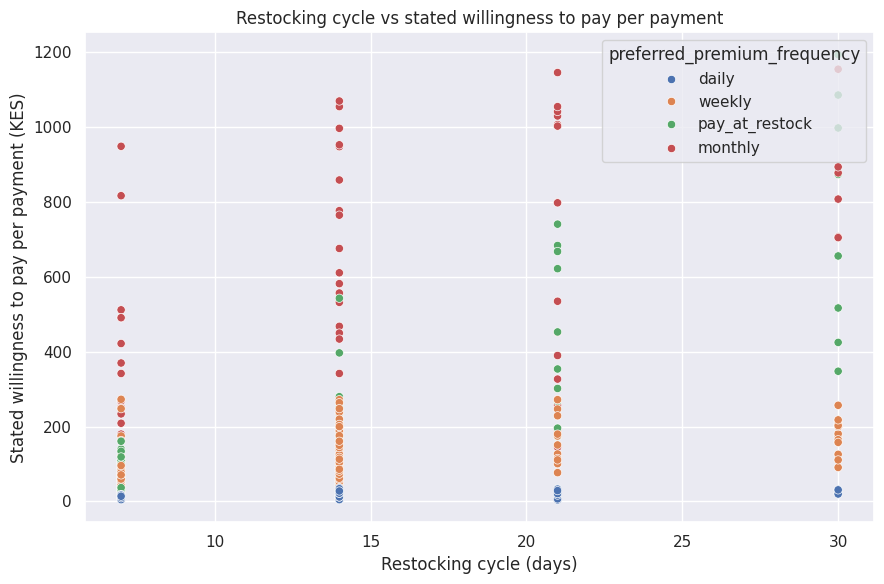

,traders,median_restock_days,median_wtp_per_payment,median_monthly_wtp
preferred_premium_frequency,,,,
weekly,110,14.0,101.5,439.5
monthly,64,14.0,491.0,491.0
pay_at_restock,64,14.0,161.0,404.0
daily,52,14.0,17.0,499.0


In [ ]:
required = {"restock_cycle_days", "wtp_per_payment_kes", "preferred_premium_frequency"}
if required.issubset(df.columns):
    plot_df = df[list(required)].dropna()
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=plot_df,
        x="restock_cycle_days",
        y="wtp_per_payment_kes",
        hue="preferred_premium_frequency"
    )
    plt.title("Restocking cycle vs stated willingness to pay per payment")
    plt.xlabel("Restocking cycle (days)")
    plt.ylabel("Stated willingness to pay per payment (KES)")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns not found:", required - set(df.columns))

# Compare median values by preferred payment frequency
display(df.groupby("preferred_premium_frequency", dropna=False).agg(
    traders=("trader_id", "count"),
    median_restock_days=("restock_cycle_days", "median"),
    median_wtp_per_payment=("wtp_per_payment_kes", "median"),
    median_monthly_wtp=("wtp_monthly_kes", "median")
).sort_values("traders", ascending=False))

## 4. Insurance lapse reasons

Filter to traders whose prior microinsurance status is `lapsed`, then summarize the recorded reasons. Check category labels in the data-quality section first.

Traders recorded as lapsed: 58


,percent,count
lapse_reason,,
slow_claims,17.2,10
too_expensive,22.4,13
claim_rejected_unclear_terms,27.6,16
stopped_paying_other,32.8,19


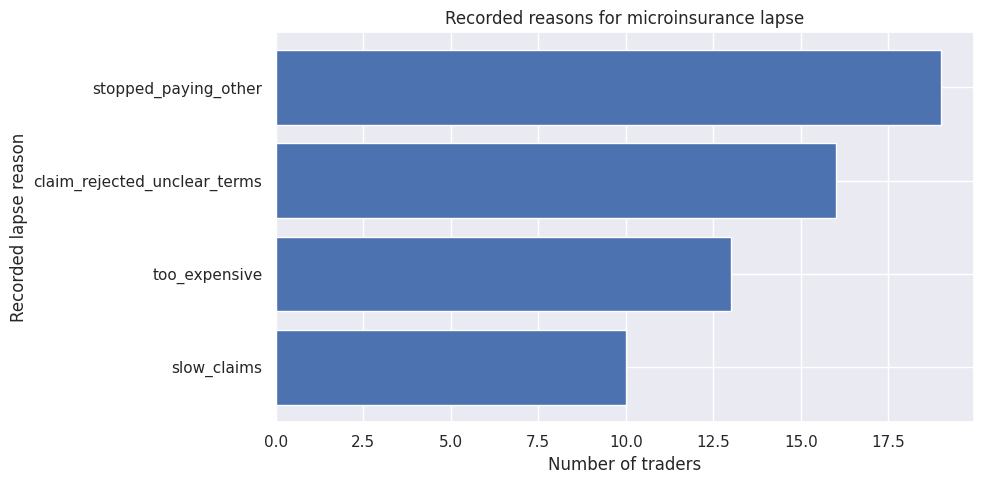

In [ ]:
lapsed = df[df["prior_microinsurance"].astype(str).str.lower().eq("lapsed")].copy()
print("Traders recorded as lapsed:", len(lapsed))

if len(lapsed) and "lapse_reason" in lapsed.columns:
    lapse_counts = lapsed["lapse_reason"].fillna("missing").value_counts().sort_values()
    display((lapse_counts / len(lapsed) * 100).round(1).rename("percent").to_frame()
            .join(lapse_counts.rename("count")))
    plt.figure(figsize=(10, 5))
    plt.barh(lapse_counts.index, lapse_counts.values)
    plt.title("Recorded reasons for microinsurance lapse")
    plt.xlabel("Number of traders")
    plt.ylabel("Recorded lapse reason")
    plt.tight_layout()
    plt.show()
else:
    print("No lapsed records or lapse_reason column available.")

## 5. Insurance awareness and trust by insurance history

Compare score distributions by prior insurance status. Means/medians are descriptive; small groups should be interpreted cautiously.

insurance_awareness_score              trust_in_insurers_score             
                                         count  mean median                   count  mean median
prior_microinsurance                                                                            
active                                      17  3.71    4.0                      17  3.82    4.0
lapsed                                      58  3.66    4.0                      58  2.50    2.0
never                                      215  2.38    2.0                     215  3.02    3.0

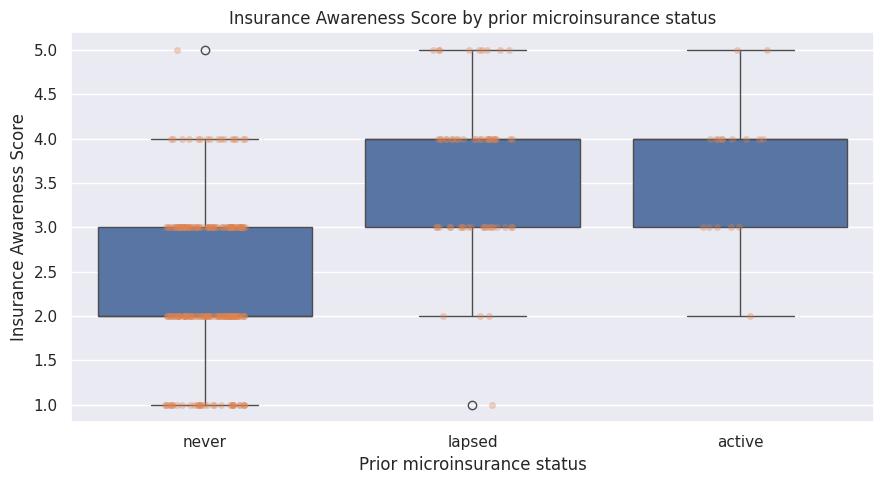

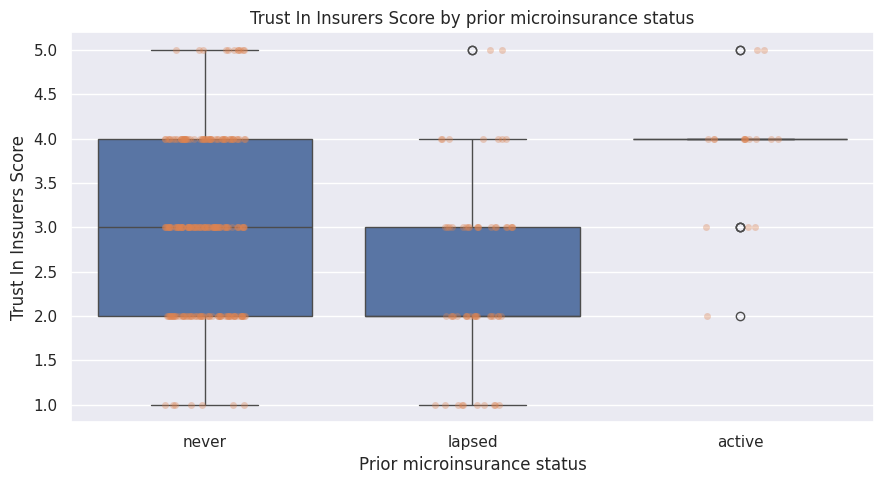

In [ ]:
score_cols = ["insurance_awareness_score", "trust_in_insurers_score"]
available_scores = [c for c in score_cols if c in df.columns]

if available_scores:
    summary = df.groupby("prior_microinsurance", dropna=False)[available_scores].agg(["count", "mean", "median"]).round(2)
    display(summary)

    for score in available_scores:
        plt.figure(figsize=(9, 5))
        sns.boxplot(data=df, x="prior_microinsurance", y=score)
        sns.stripplot(data=df, x="prior_microinsurance", y=score, alpha=0.35, jitter=0.15)
        plt.title(f"{score.replace('_', ' ').title()} by prior microinsurance status")
        plt.xlabel("Prior microinsurance status")
        plt.ylabel(score.replace("_", " ").title())
        plt.tight_layout()
        plt.show()

## 6. Digital access, preferred channel and language

### 6A. Overall preferred channel

,count,percent
preferred_channel,,
whatsapp,115,39.7
ussd,103,35.5
either,72,24.8


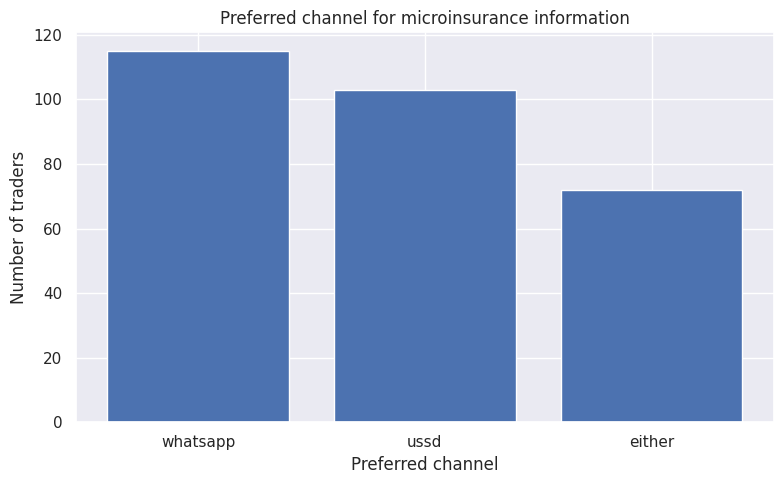

smartphone_owner,False,True,All
preferred_channel,,,
either,0,72,72
ussd,17,86,103
whatsapp,0,115,115
All,17,273,290


whatsapp_user,False,True,All
preferred_channel,,,
either,6,66,72
ussd,28,75,103
whatsapp,0,115,115
All,34,256,290


In [ ]:
channel_counts = df["preferred_channel"].fillna("missing").value_counts()
channel_pct = (channel_counts / channel_counts.sum() * 100).round(1)
display(pd.DataFrame({"count": channel_counts, "percent": channel_pct}))

plt.figure(figsize=(8, 5))
plt.bar(channel_counts.index, channel_counts.values)
plt.title("Preferred channel for microinsurance information")
plt.xlabel("Preferred channel")
plt.ylabel("Number of traders")
plt.tight_layout()
plt.show()

# Access checks: ownership/use versus stated channel preference
access_cols = ["smartphone_owner", "whatsapp_user"]
display(pd.crosstab(df["preferred_channel"], df["smartphone_owner"], margins=True))
display(pd.crosstab(df["preferred_channel"], df["whatsapp_user"], margins=True))

### 6B. Preferred language × channel preference (row percentages)

preferred_channel,either,ussd,whatsapp
language_pref,,,
english,30.1,30.1,39.8
sheng,17.2,46.9,35.9
swahili,25.2,33.6,41.3


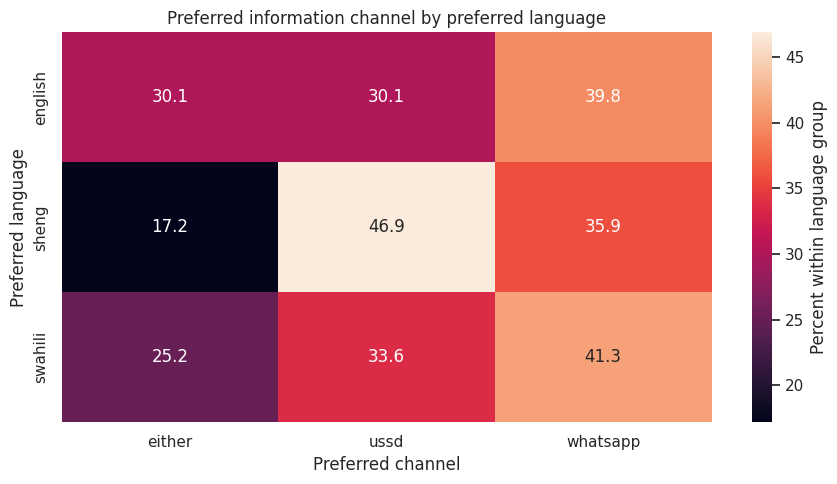

In [ ]:
lang_channel = pd.crosstab(df["language_pref"], df["preferred_channel"], normalize="index") * 100
display(lang_channel.round(1))

plt.figure(figsize=(9, 5))
sns.heatmap(lang_channel, annot=True, fmt=".1f", cbar_kws={"label": "Percent within language group"})
plt.title("Preferred information channel by preferred language")
plt.xlabel("Preferred channel")
plt.ylabel("Preferred language")
plt.tight_layout()
plt.show()

## 7. Exploratory trader segmentation

This section creates transparent, rule-based *candidate* segments for exploration. The rules are illustrative and should be reviewed with traders and insurance providers before being used operationally. A trader may fit more than one segment.

,segment,traders,percent_of_dataset
0,high_stock_exposure,73,25.2
1,cash_flow_constrained_candidate,57,19.7
2,information_seeking_candidate,124,42.8
3,previously_lapsed,58,20.0
4,digital_access_constraint_candidate,34,11.7


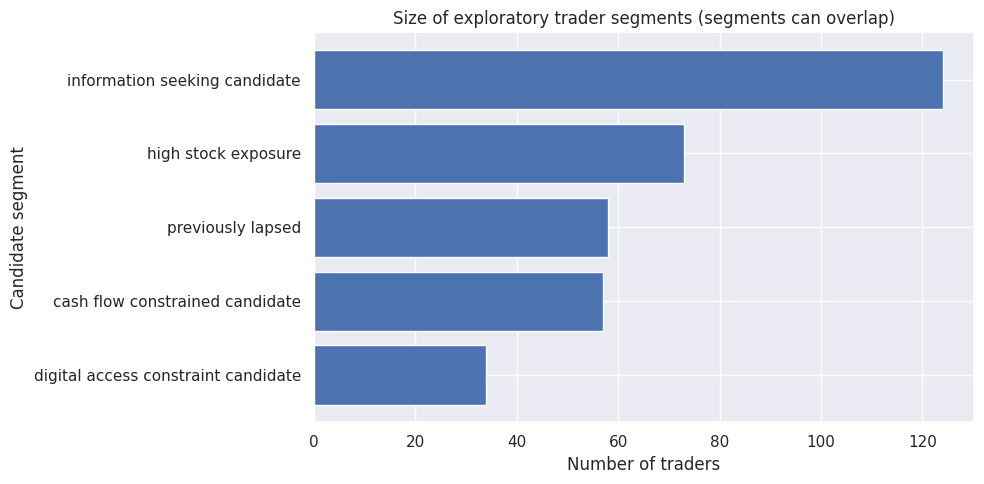

,segment,traders,median_monthly_income_kes,median_stock_value_kes,median_monthly_wtp_kes,most_common_primary_risk,most_common_channel
0,high_stock_exposure,73,94000.0,282000.0,880.0,health,ussd
1,cash_flow_constrained_candidate,57,22500.0,70000.0,266.0,fire,either
2,information_seeking_candidate,124,42000.0,131500.0,451.0,fire,ussd
3,previously_lapsed,58,37500.0,119000.0,418.0,fire,ussd
4,digital_access_constraint_candidate,34,38250.0,146500.0,483.0,theft,ussd


In [ ]:
seg = df.copy()

# Normalize booleans robustly if values are already booleans or contain strings.
def as_bool(series):
    if pd.api.types.is_bool_dtype(series):
        return series
    return series.astype(str).str.strip().str.lower().map({
        "true": True, "1": True, "yes": True,
        "false": False, "0": False, "no": False
    })

seg["high_stock_exposure"] = (
    seg["stock_value_kes"].ge(seg["stock_value_kes"].quantile(0.75))
    if "stock_value_kes" in seg else False
)
seg["cash_flow_constrained_candidate"] = (
    seg["income_variability"].astype(str).str.lower().eq("high")
)
seg["information_seeking_candidate"] = (
    seg["insurance_awareness_score"].le(2)
    if "insurance_awareness_score" in seg else False
)
seg["previously_lapsed"] = seg["prior_microinsurance"].astype(str).str.lower().eq("lapsed")
seg["digital_access_constraint_candidate"] = (
    (~as_bool(seg["smartphone_owner"]).fillna(False)) |
    (~as_bool(seg["whatsapp_user"]).fillna(False))
)

# Summarize overlap: these segments are not mutually exclusive.
segment_cols = [
    "high_stock_exposure", "cash_flow_constrained_candidate",
    "information_seeking_candidate", "previously_lapsed",
    "digital_access_constraint_candidate"
]
segment_summary = pd.DataFrame({
    "segment": segment_cols,
    "traders": [seg[c].fillna(False).sum() for c in segment_cols]
})
segment_summary["percent_of_dataset"] = (segment_summary["traders"] / len(seg) * 100).round(1)
display(segment_summary)

plt.figure(figsize=(10, 5))
ordered = segment_summary.sort_values("traders")
plt.barh(ordered["segment"].str.replace("_", " "), ordered["traders"])
plt.title("Size of exploratory trader segments (segments can overlap)")
plt.xlabel("Number of traders")
plt.ylabel("Candidate segment")
plt.tight_layout()
plt.show()

# Compare segment characteristics; medians are robust for skewed money variables.
segment_profiles = []
for col in segment_cols:
    group = seg[seg[col].fillna(False)]
    segment_profiles.append({
        "segment": col,
        "traders": len(group),
        "median_monthly_income_kes": group["monthly_income_kes"].median(),
        "median_stock_value_kes": group["stock_value_kes"].median(),
        "median_monthly_wtp_kes": group["wtp_monthly_kes"].median(),
        "most_common_primary_risk": group["primary_risk_concern"].mode().iat[0] if not group["primary_risk_concern"].mode().empty else np.nan,
        "most_common_channel": group["preferred_channel"].mode().iat[0] if not group["preferred_channel"].mode().empty else np.nan
    })
display(pd.DataFrame(segment_profiles).round(1))

## 8. Stated willingness to pay and financial circumstances

### 8A. Monthly income vs stated monthly willingness to pay

Use a scatter plot and Spearman correlation. Correlation is association, not causation.

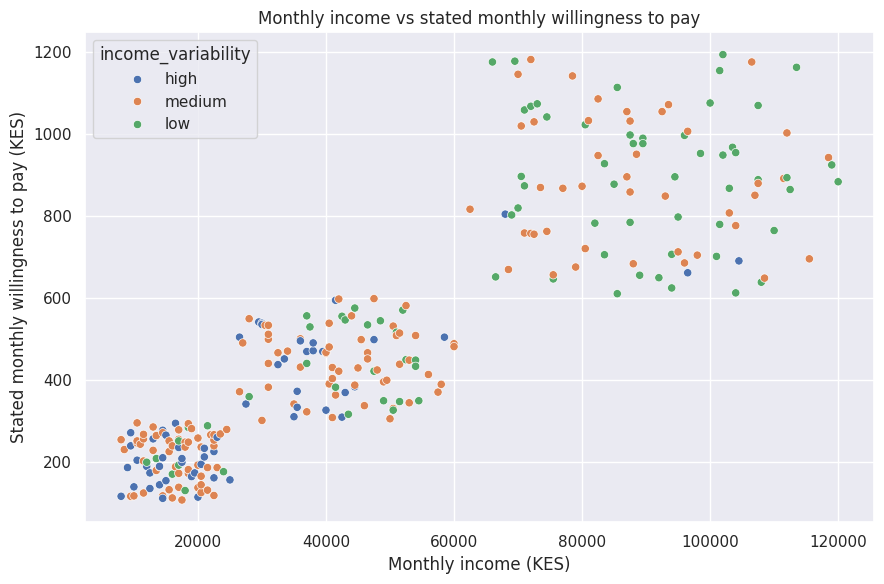

,monthly_income_kes,wtp_monthly_kes
monthly_income_kes,1.000,0.886
wtp_monthly_kes,0.886,1.000


,traders,median_income_kes,median_monthly_wtp_kes,median_wtp_per_payment_kes
income_variability,,,,
high,57,22500.0,266.0,52.0
low,82,73750.0,706.5,203.5
medium,151,40500.0,425.0,119.0


In [ ]:
plot_cols = ["monthly_income_kes", "wtp_monthly_kes", "income_variability"]
plot_df = df[plot_cols].dropna()
plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="monthly_income_kes", y="wtp_monthly_kes", hue="income_variability")
plt.title("Monthly income vs stated monthly willingness to pay")
plt.xlabel("Monthly income (KES)")
plt.ylabel("Stated monthly willingness to pay (KES)")
plt.tight_layout()
plt.show()

display(plot_df[["monthly_income_kes", "wtp_monthly_kes"]].corr(method="spearman").round(3))

# Summarize willingness to pay across key groups
display(df.groupby("income_variability", dropna=False).agg(
    traders=("trader_id", "count"),
    median_income_kes=("monthly_income_kes", "median"),
    median_monthly_wtp_kes=("wtp_monthly_kes", "median"),
    median_wtp_per_payment_kes=("wtp_per_payment_kes", "median")
).round(1))

### 8B. Compare willingness to pay by primary risk and insurance history

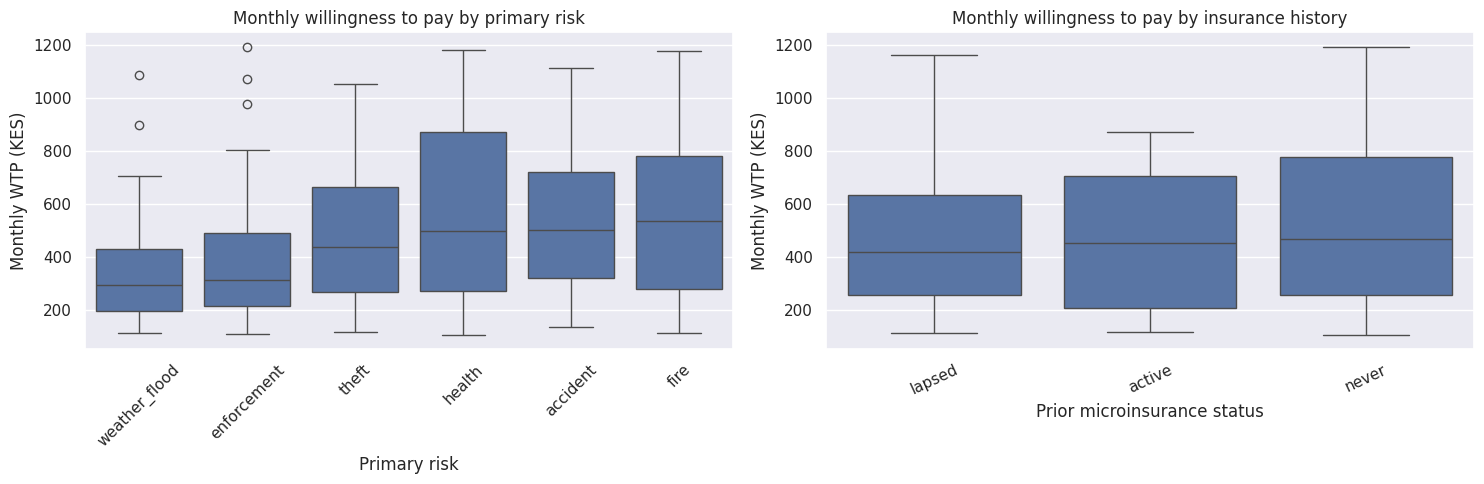

traders  median_monthly_wtp_kes  mean_monthly_wtp_kes
primary_risk_concern prior_microinsurance                                                       
accident             active                      1                   499.0                 499.0
                     lapsed                      4                   269.5                 431.0
                     never                      13                   534.0                 587.2
enforcement          active                      5                   267.0                 382.2
                     lapsed                      3                   311.0                 299.7
                     never                      22                   343.5                 427.3
fire                 active                      2                   790.0                 790.0
                     lapsed                     18                   549.5                 543.3
                     never                      61                   501.0                 557.1
health               active                      5                   489.0                 457.0
                     lapsed                     17                   422.0                 570.5
                     never                      55                   532.0                 580.5
theft                active                      2                   590.0                 590.0
                     lapsed                     12                   365.0                 441.8
                     never                      46                   443.5                 490.5
weather_flood        active                      2                   131.5                 131.5
                     lapsed                      4                   298.0                 283.5
                     never                      18                   321.5                 405.5

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

risk_order = df.groupby("primary_risk_concern")["wtp_monthly_kes"].median().sort_values().index
sns.boxplot(data=df, x="primary_risk_concern", y="wtp_monthly_kes", order=risk_order, ax=axes[0])
axes[0].set_title("Monthly willingness to pay by primary risk")
axes[0].set_xlabel("Primary risk")
axes[0].set_ylabel("Monthly WTP (KES)")
axes[0].tick_params(axis="x", rotation=45)

status_order = df.groupby("prior_microinsurance")["wtp_monthly_kes"].median().sort_values().index
sns.boxplot(data=df, x="prior_microinsurance", y="wtp_monthly_kes", order=status_order, ax=axes[1])
axes[1].set_title("Monthly willingness to pay by insurance history")
axes[1].set_xlabel("Prior microinsurance status")
axes[1].set_ylabel("Monthly WTP (KES)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# Non-parametric group comparison summaries; inspect sample sizes before interpreting.
display(df.groupby(["primary_risk_concern", "prior_microinsurance"], dropna=False).agg(
    traders=("trader_id", "count"),
    median_monthly_wtp_kes=("wtp_monthly_kes", "median"),
    mean_monthly_wtp_kes=("wtp_monthly_kes", "mean")
).round(1))

## 9. Optional: simple statistical tests

Use these only after inspecting distributions, group sizes, and data collection methods. P-values do not measure practical importance and do not establish causality.

In [ ]:
from scipy.stats import spearmanr, kruskal, chi2_contingency

# Spearman association between income and monthly willingness to pay
tmp = df[["monthly_income_kes", "wtp_monthly_kes"]].dropna()
if len(tmp) >= 3:
    rho, p = spearmanr(tmp["monthly_income_kes"], tmp["wtp_monthly_kes"])
    print(f"Spearman income-WTP: rho={rho:.3f}, p={p:.4g}, n={len(tmp)}")

# Kruskal-Wallis test: monthly WTP across income-variability groups
groups = [
    g["wtp_monthly_kes"].dropna().values
    for _, g in df.groupby("income_variability")
    if g["wtp_monthly_kes"].notna().sum() > 0
]
if len(groups) >= 2 and all(len(g) > 0 for g in groups):
    stat, p = kruskal(*groups)
    print(f"Kruskal-Wallis WTP by income variability: H={stat:.3f}, p={p:.4g}")

# Chi-square: preferred channel vs preferred language
ct = pd.crosstab(df["language_pref"], df["preferred_channel"])
if ct.shape[0] > 1 and ct.shape[1] > 1:
    chi2, p, dof, expected = chi2_contingency(ct)
    print(f"Chi-square language-channel: chi2={chi2:.3f}, dof={dof}, p={p:.4g}")
    print("Check expected cell counts before interpreting this test.")

Spearman income-WTP: rho=0.886, p=4.808e-98, n=290
Kruskal-Wallis WTP by income variability: H=55.823, p=7.552e-13
Chi-square language-channel: chi2=5.923, dof=4, p=0.205
Check expected cell counts before interpreting this test.


## 10. Export summary tables

This writes analysis tables to an `outputs` folder. Charts can be saved individually by adding `plt.savefig(...)` before each `plt.show()`.

In [ ]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

df.isna().sum().rename("missing_count").to_csv(OUTPUT_DIR / "missing_values.csv")
risk_summary.to_csv(OUTPUT_DIR / "primary_risk_summary.csv")
cover_summary.to_csv(OUTPUT_DIR / "coverage_interest_summary.csv")
ct.to_csv(OUTPUT_DIR / "last_crosstab.csv")

print(f"Summary tables exported to: {OUTPUT_DIR.resolve()}")

Summary tables exported to: /content/outputs


Trader Segmentation - K-means Clustering

In [ ]:
features = [
    "primary_risk_concern",
    "wants_cover_fire",
    "wants_cover_theft",
    "stock_value_kes",
    "total_loss_24m_kes",
    "monthly_income_kes",
    "income_variability",
    "wtp_monthly_kes",
    "preferred_premium_frequency",
    "income_receipt_pattern",
    "restock_cycle_days"
]

display(df[features].describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
primary_risk_concern,290,6,fire,81,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wants_cover_fire,290,2,True,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wants_cover_theft,290,2,False,160,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stock_value_kes,290.0,NaN,NaN,NaN,146689.655172,98318.036111,15000.0,64500.0,129500.0,203750.0,396000.0
total_loss_24m_kes,290.0,NaN,NaN,NaN,24832.758621,44005.293752,0.0,0.0,5000.0,32250.0,354000.0
monthly_income_kes,290.0,NaN,NaN,NaN,49651.724138,32116.425539,8000.0,20125.0,42250.0,75500.0,120000.0
income_variability,290,3,medium,151,NaN,NaN,NaN,NaN,NaN,NaN,NaN
wtp_monthly_kes,290.0,NaN,NaN,NaN,513.989655,302.149995,108.0,255.25,451.0,757.5,1194.0
preferred_premium_frequency,290,4,weekly,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_receipt_pattern,290,3,daily,235,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_features = [
    "stock_value_kes",
    "total_loss_24m_kes",
    "monthly_income_kes",
    "wtp_monthly_kes",
    "restock_cycle_days"
]

categorical_features = [
    "primary_risk_concern",
    "wants_cover_fire",
    "wants_cover_theft",
    "income_variability",
    "preferred_premium_frequency",
    "income_receipt_pattern"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X = df[numeric_features + categorical_features]

X_processed = preprocessor.fit_transform(X)

print("Original shape:", X.shape)
print("Processed shape:", X_processed.shape)

Original shape: (290, 11)
Processed shape: (290, 25)


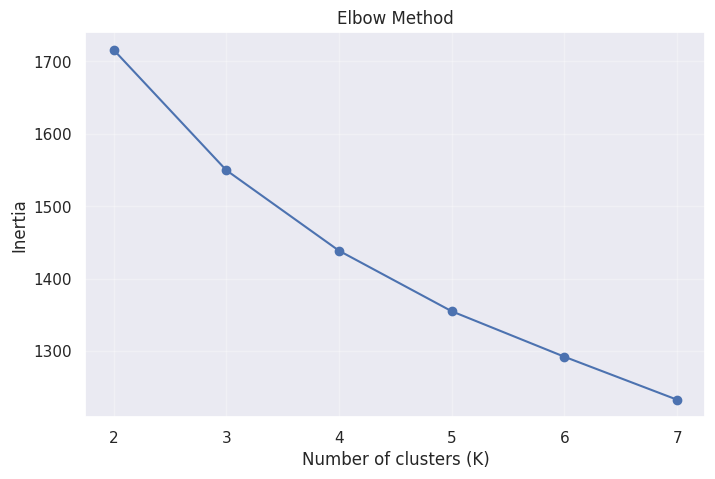

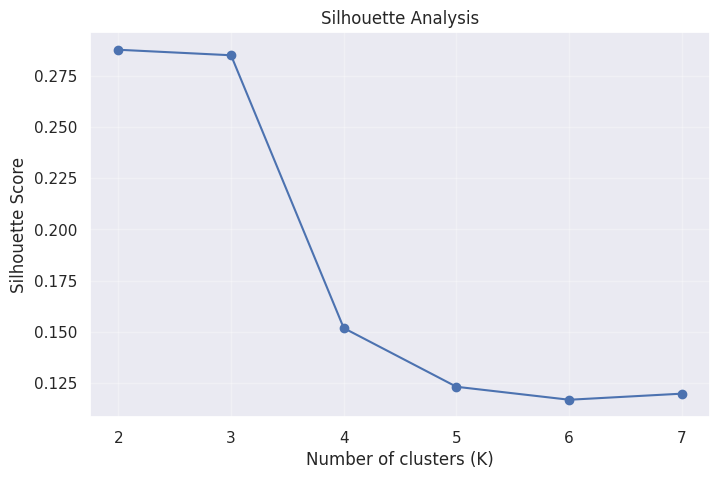

K=2: Silhouette Score=0.288
K=3: Silhouette Score=0.285
K=4: Silhouette Score=0.152
K=5: Silhouette Score=0.123
K=6: Silhouette Score=0.117
K=7: Silhouette Score=0.120


In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia_values = []
silhouette_values = []
k_values = range(2, 8)

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_processed)

    inertia_values.append(model.inertia_)
    silhouette_values.append(
        silhouette_score(X_processed, labels)
    )

# Elbow plot
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_values, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

# Silhouette plot
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), silhouette_values, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

for k, score in zip(k_values, silhouette_values):
    print(f"K={k}: Silhouette Score={score:.3f}")

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

df["cluster"] = kmeans.fit_predict(X_processed)

print(df["cluster"].value_counts().sort_index())

cluster
0     16
1     88
2    186
Name: count, dtype: int64


In [ ]:
cluster_numeric = df.groupby("cluster")[numeric_features].median()

display(cluster_numeric.round(2))

,stock_value_kes,total_loss_24m_kes,monthly_income_kes,wtp_monthly_kes,restock_cycle_days
cluster,,,,,
0,257500.0,142500.0,88250.0,805.5,21.0
1,248000.0,0.0,87500.0,873.5,21.0
2,77000.0,10000.0,23750.0,291.5,14.0


In [ ]:
for col in categorical_features:
    print(f"\n--- {col} ---")

    distribution = pd.crosstab(
        df["cluster"],
        df[col],
        normalize="index"
    ) * 100

    display(distribution.round(1))


--- primary_risk_concern ---


primary_risk_concern,accident,enforcement,fire,health,theft,weather_flood
cluster,,,,,,
0,6.2,12.5,37.5,25.0,18.8,0.0
1,5.7,2.3,36.4,34.1,17.0,4.5
2,6.5,14.0,23.1,23.1,22.6,10.8



--- wants_cover_fire ---


wants_cover_fire,False,True
cluster,,
0,18.8,81.2
1,39.8,60.2
2,55.9,44.1



--- wants_cover_theft ---


wants_cover_theft,False,True
cluster,,
0,56.2,43.8
1,62.5,37.5
2,51.6,48.4


... (2 outputs left out)


--- preferred_premium_frequency ---


preferred_premium_frequency,daily,monthly,pay_at_restock,weekly
cluster,,,,
0,18.8,18.8,0.0,62.5
1,20.5,27.3,15.9,36.4
2,16.7,19.9,26.9,36.6



--- income_receipt_pattern ---


income_receipt_pattern,daily,monthly,weekly
cluster,,,
0,75.0,6.2,18.8
1,64.8,9.1,26.1
2,89.2,2.7,8.1


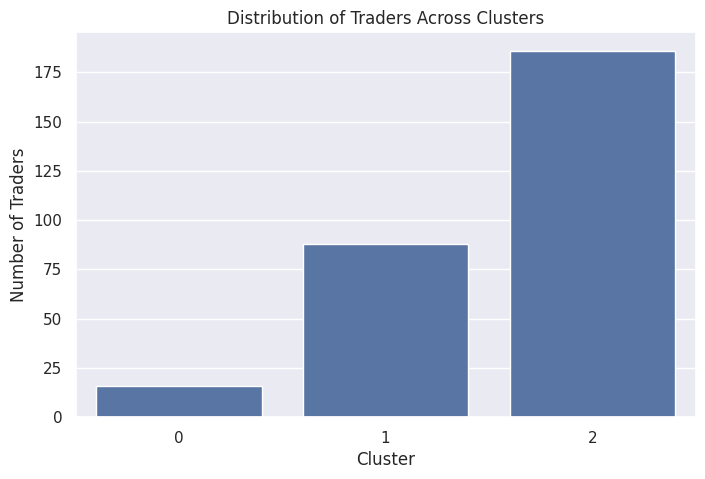

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="cluster"
)

plt.title("Distribution of Traders Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Traders")

plt.show()

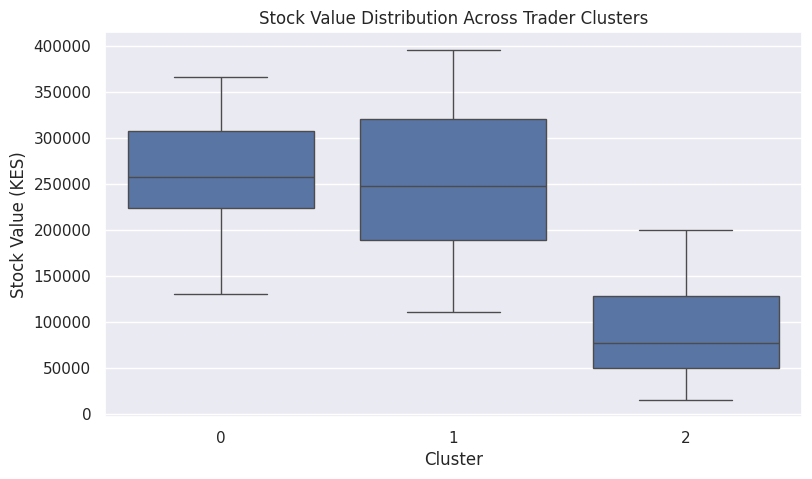

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="cluster",
    y="stock_value_kes"
)

plt.title("Stock Value Distribution Across Trader Clusters")
plt.xlabel("Cluster")
plt.ylabel("Stock Value (KES)")

plt.show()

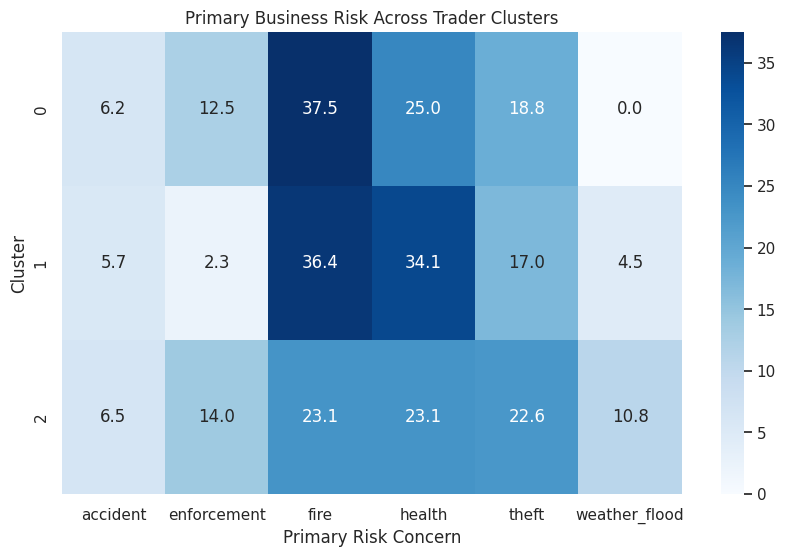

In [ ]:
risk_distribution = pd.crosstab(
    df["cluster"],
    df["primary_risk_concern"],
    normalize="index"
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    risk_distribution,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("Primary Business Risk Across Trader Clusters")
plt.xlabel("Primary Risk Concern")
plt.ylabel("Cluster")

plt.show()

In [ ]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np

# Initialize PCA with two components
pca = PCA(n_components=2)

# Transform the processed dataset
X_pca = pca.fit_transform(X_processed)

# Create a DataFrame containing the PCA results
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

# Add cluster assignments
pca_df["cluster"] = df["cluster"].values

# Inspect results
display(pca_df.head())

,PC1,PC2,cluster
0,-2.506235,-0.034977,2
1,-1.712669,0.457918,2
2,-2.188491,-0.367922,2
3,-2.113268,-0.124974,2
4,-2.529322,-0.432296,2


In [ ]:
# Individual explained variance
explained_variance = pca.explained_variance_ratio_

# Cumulative explained variance
cumulative_variance = np.cumsum(explained_variance)

print(f"PC1: {explained_variance[0]*100:.2f}%")
print(f"PC2: {explained_variance[1]*100:.2f}%")

print(
    f"Total variance explained: "
    f"{sum(explained_variance)*100:.2f}%"
)

PC1: 37.37%
PC2: 12.09%
Total variance explained: 49.46%


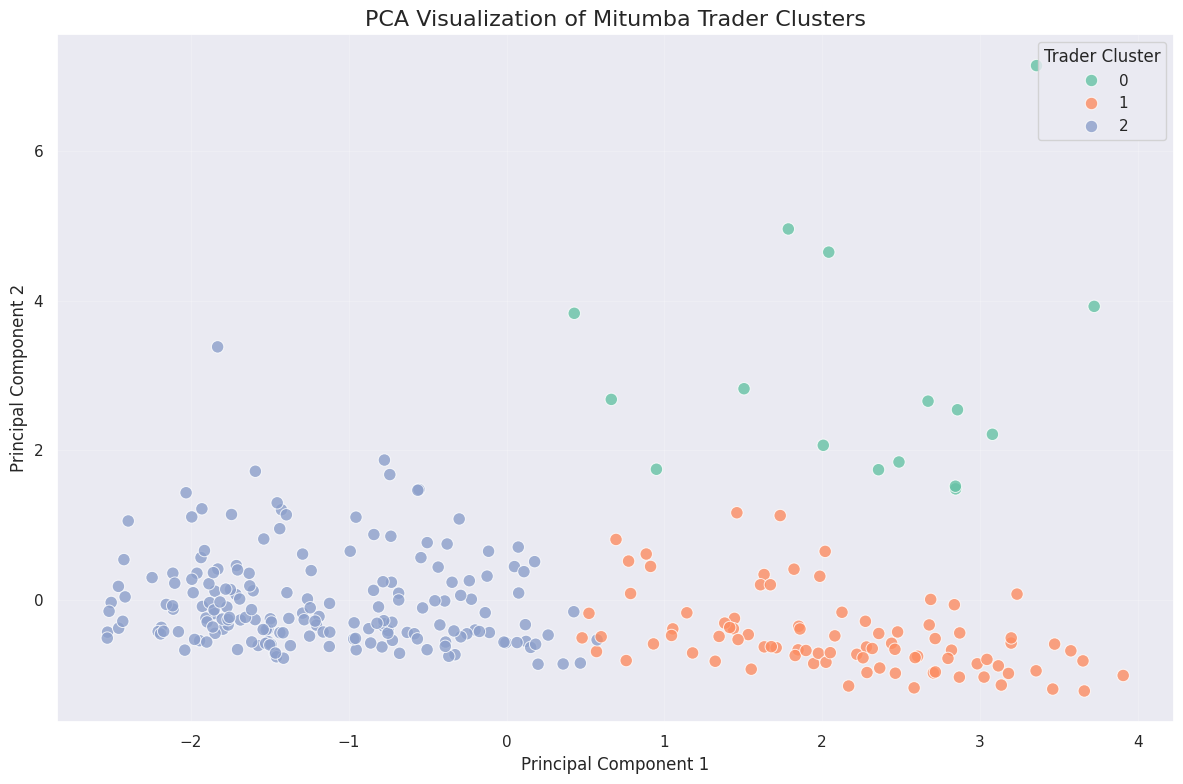

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    s=80,
    alpha=0.8
)

plt.title(
    "PCA Visualization of Mitumba Trader Clusters",
    fontsize=16
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(title="Trader Cluster")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

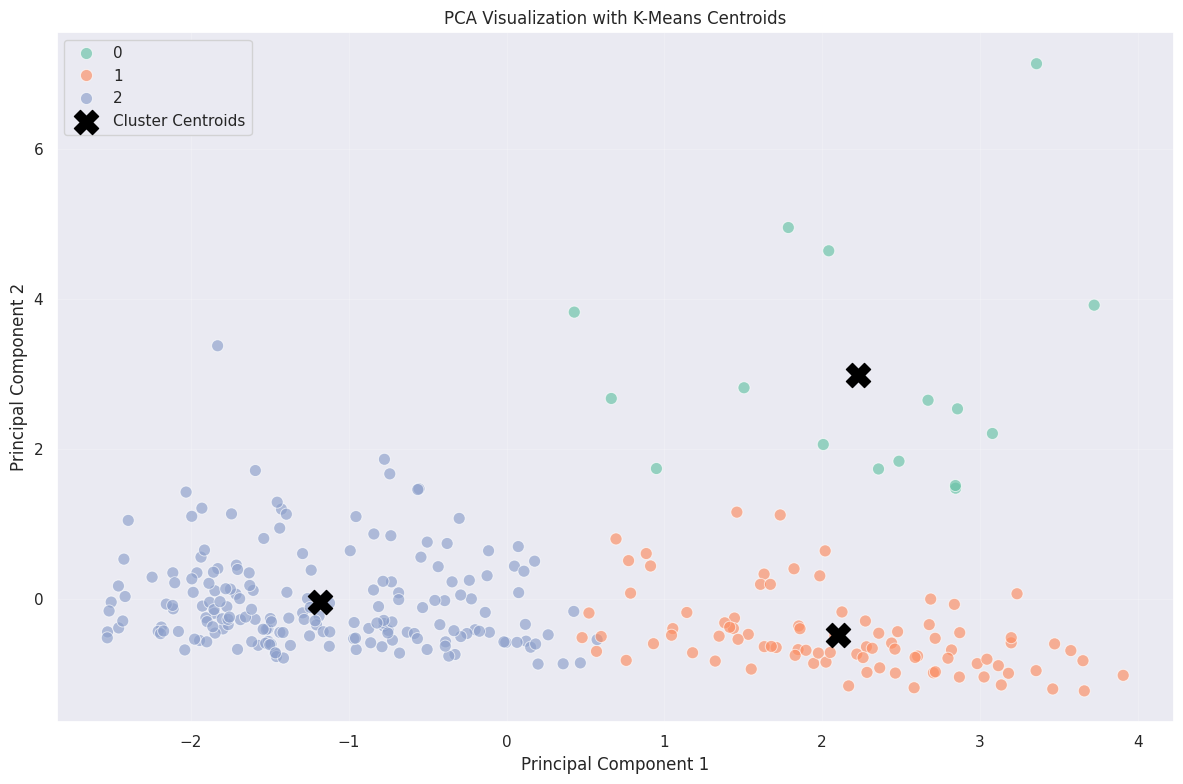

In [ ]:
# Transform K-Means centroids into PCA space
centroids_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    s=75,
    alpha=0.65
)

# Plot centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker="X",
    s=300,
    color="black",
    label="Cluster Centroids"
)

plt.title("PCA Visualization with K-Means Centroids")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Extract PCA loadings
loadings = pd.DataFrame(
    pca.components_.T,
    columns=["PC1", "PC2"],
    index=feature_names
)

display(loadings)

,PC1,PC2
num__stock_value_kes,0.522113,-0.021438
num__total_loss_24m_kes,0.079800,0.964515
num__monthly_income_kes,0.540989,-0.022500
num__wtp_monthly_kes,0.512419,-0.018419
num__restock_cycle_days,0.354546,-0.097070
cat__primary_risk_concern_accident,0.002044,-0.001514
cat__primary_risk_concern_enforcement,-0.028328,0.016463
cat__primary_risk_concern_fire,0.038883,0.029391
cat__primary_risk_concern_health,0.028347,-0.048823
cat__primary_risk_concern_theft,-0.019802,0.016864


#### 11. Linking Trader Clusters to an Insurance Product Catalogue



In [ ]:
# Load the actual Britam product catalogue
britam_products_path = "/content/drive/MyDrive/ReCover/Recommendation_system/Data/britam_biashara_lite_products.csv"
britam_df = pd.read_csv(britam_products_path)

print("Britam Product Catalogue columns and shape:", britam_df.shape)
display(britam_df.head(20))


Britam Product Catalogue columns and shape: (5, 19)


,product_id,product_family,target_segment,plan_name,tier_rank,premium_kes_pa,fire_limit_kes,fire_consequential_limit_kes,burglary_limit_kes,all_risks_limit_kes,money_limit_kes,fidelity_guarantee_limit_kes,gpa_wiba_named_staff,gpa_wiba_benefit_per_staff_kes,group_last_expense_named_staff,group_last_expense_benefit_per_staff_kes,public_liability_limit_kes,political_violence_terrorism_limit_kes,pa_one_director_limit_kes
0,BBL-ELITE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Elite,1,6933,500000,250000,500000,100000,50000,50000,2,75000,2,50000,1000000,500000,100000
1,BBL-PREMIUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Premium,2,13615,1000000,500000,1000000,200000,100000,100000,4,75000,4,50000,2000000,1000000,100000
2,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000,750000,1500000,300000,150000,150000,6,75000,6,50000,3000000,1500000,100000
3,BBL-PLATINUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Platinum,4,26980,2000000,1000000,2000000,400000,200000,200000,8,75000,8,50000,4000000,2000000,100000
4,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000,1500000,3000000,500000,500000,250000,10,75000,10,50000,5000000,3000000,100000


In [ ]:
print("Top contributors to PC1:")
display(
    loadings["PC1"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

print("Top contributors to PC2:")
display(
    loadings["PC2"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

Top contributors to PC1:


,PC1
num__monthly_income_kes,0.540989
num__stock_value_kes,0.522113
num__wtp_monthly_kes,0.512419
num__restock_cycle_days,0.354546
cat__income_variability_low,0.118527
num__total_loss_24m_kes,0.079800
cat__income_variability_high,0.079767
cat__income_receipt_pattern_daily,0.060669
cat__wants_cover_fire_False,0.048914
cat__wants_cover_fire_True,0.048914


Top contributors to PC2:


,PC2
num__total_loss_24m_kes,0.964515
cat__wants_cover_fire_True,0.107878
cat__wants_cover_fire_False,0.107878
num__restock_cycle_days,0.097070
cat__preferred_premium_frequency_weekly,0.090850
cat__income_variability_low,0.080388
cat__wants_cover_theft_True,0.068579
cat__wants_cover_theft_False,0.068579
cat__income_variability_medium,0.057284
cat__primary_risk_concern_health,0.048823


In [ ]:
print('--- Top 5 Features for PC1 (Absolute Loadings) ---')
display(loadings['PC1'].abs().sort_values(ascending=False).head(5))

print('\n--- Top 5 Features for PC2 (Absolute Loadings) ---')
display(loadings['PC2'].abs().sort_values(ascending=False).head(5))

--- Top 5 Features for PC1 (Absolute Loadings) ---


,PC1
num__monthly_income_kes,0.540989
num__stock_value_kes,0.522113
num__wtp_monthly_kes,0.512419
num__restock_cycle_days,0.354546
cat__income_variability_low,0.118527



--- Top 5 Features for PC2 (Absolute Loadings) ---


,PC2
num__total_loss_24m_kes,0.964515
cat__wants_cover_fire_True,0.107878
cat__wants_cover_fire_False,0.107878
num__restock_cycle_days,0.097070
cat__preferred_premium_frequency_weekly,0.090850


#### Product matching

In [ ]:
import pandas as pd
import numpy as np

# Load datasets
traders = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/Traders_dataset.csv")

products = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/britam_biashara_lite_products.csv")

print("Traders:", traders.shape)
print("Products:", products.shape)

display(products)

Traders: (290, 50)
Products: (5, 19)


,product_id,product_family,target_segment,plan_name,tier_rank,premium_kes_pa,fire_limit_kes,fire_consequential_limit_kes,burglary_limit_kes,all_risks_limit_kes,money_limit_kes,fidelity_guarantee_limit_kes,gpa_wiba_named_staff,gpa_wiba_benefit_per_staff_kes,group_last_expense_named_staff,group_last_expense_benefit_per_staff_kes,public_liability_limit_kes,political_violence_terrorism_limit_kes,pa_one_director_limit_kes
0,BBL-ELITE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Elite,1,6933,500000,250000,500000,100000,50000,50000,2,75000,2,50000,1000000,500000,100000
1,BBL-PREMIUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Premium,2,13615,1000000,500000,1000000,200000,100000,100000,4,75000,4,50000,2000000,1000000,100000
2,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000,750000,1500000,300000,150000,150000,6,75000,6,50000,3000000,1500000,100000
3,BBL-PLATINUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Platinum,4,26980,2000000,1000000,2000000,400000,200000,200000,8,75000,8,50000,4000000,2000000,100000
4,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000,1500000,3000000,500000,500000,250000,10,75000,10,50000,5000000,3000000,100000


#### Business related insurance needs

In [ ]:
business_risk_columns = [
    "wants_cover_fire",
    "wants_cover_theft"
]

# Create a business risk profile
traders["business_risks"] = traders.apply(
    lambda row: [
        risk for risk, column in {
            "fire": "wants_cover_fire",
            "theft": "wants_cover_theft"
        }.items()
        if row[column] == True
    ],
    axis=1
)

display(
    traders[
        ["trader_id", "primary_risk_concern",
         "business_risks", "stock_value_kes"]
    ].head(10)
)

,trader_id,primary_risk_concern,business_risks,stock_value_kes
0,T0109,fire,[fire],15000
1,T0925,fire,"[fire, theft]",54000
2,T0366,health,[fire],41000
3,T0322,theft,"[fire, theft]",17000
4,T0069,accident,[],15000
5,T0183,theft,"[fire, theft]",53000
6,T0928,theft,[theft],64000
7,T0248,enforcement,[],57000
8,T0744,health,[],28000
9,T0763,weather_flood,[theft],47000


#### Calculate affordability

In [ ]:
products["monthly_premium_kes"] = (
    products["premium_kes_pa"] / 12
)

products["weekly_equivalent_kes"] = (
    products["premium_kes_pa"] / 52
)

display(
    products[
        ["plan_name", "premium_kes_pa",
         "monthly_premium_kes",
         "weekly_equivalent_kes"]
    ].round(2)
)

,plan_name,premium_kes_pa,monthly_premium_kes,weekly_equivalent_kes
0,Elite,6933,577.75,133.33
1,Premium,13615,1134.58,261.83
2,Diamond,20298,1691.50,390.35
3,Platinum,26980,2248.33,518.85
4,Prestige,37163,3096.92,714.67


#### Product matching function

In [ ]:
def match_products(trader, products):

    results = []

    stock_value = trader["stock_value_kes"]
    monthly_wtp = trader["wtp_monthly_kes"]

    risks = trader["business_risks"]

    # No matching recommendation if no relevant risk is identified
    if not risks:
        return pd.DataFrame()

    for _, product in products.iterrows():

        risk_matches = []

        if "fire" in risks and product["fire_limit_kes"] > 0:
            risk_matches.append("fire")

        if "theft" in risks and product["burglary_limit_kes"] > 0:
            risk_matches.append("theft")

        if not risk_matches:
            continue

        # Determine relevant coverage limits
        relevant_limits = []

        if "fire" in risks:
            relevant_limits.append(product["fire_limit_kes"])

        if "theft" in risks:
            relevant_limits.append(product["burglary_limit_kes"])

        # Use the lowest relevant limit as a conservative
        # coverage adequacy indicator
        coverage_limit = min(relevant_limits)

        coverage_ratio = min(
            coverage_limit / max(stock_value, 1),
            1
        )

        monthly_premium = product["premium_kes_pa"] / 12

        affordable = monthly_premium <= monthly_wtp

        results.append({

            "trader_id": trader["trader_id"],

            "product_id": product["product_id"],

            "plan_name": product["plan_name"],

            "risk_match": risk_matches,

            "coverage_limit_kes": coverage_limit,

            "coverage_ratio": coverage_ratio,

            "annual_premium_kes": product["premium_kes_pa"],

            "monthly_premium_kes": monthly_premium,

            "monthly_wtp_kes": monthly_wtp,

            "affordable": affordable

        })

    return pd.DataFrame(results)

#### Generate recommendations for traders

In [ ]:
all_matches = []

for _, trader in traders.iterrows():

    matches = match_products(trader, products)

    if not matches.empty:
        all_matches.append(matches)

recommendations = pd.concat(
    all_matches,
    ignore_index=True
)

display(recommendations.head(20))

,trader_id,product_id,plan_name,risk_match,coverage_limit_kes,coverage_ratio,annual_premium_kes,monthly_premium_kes,monthly_wtp_kes,affordable
0,T0109,BBL-ELITE,Elite,[fire],500000,1,6933,577.750000,117,False
1,T0109,BBL-PREMIUM,Premium,[fire],1000000,1,13615,1134.583333,117,False
2,T0109,BBL-DIAMOND,Diamond,[fire],1500000,1,20298,1691.500000,117,False
3,T0109,BBL-PLATINUM,Platinum,[fire],2000000,1,26980,2248.333333,117,False
4,T0109,BBL-PRESTIGE,Prestige,[fire],3000000,1,37163,3096.916667,117,False
5,T0925,BBL-ELITE,Elite,"[fire, theft]",500000,1,6933,577.750000,255,False
6,T0925,BBL-PREMIUM,Premium,"[fire, theft]",1000000,1,13615,1134.583333,255,False
7,T0925,BBL-DIAMOND,Diamond,"[fire, theft]",1500000,1,20298,1691.500000,255,False
8,T0925,BBL-PLATINUM,Platinum,"[fire, theft]",2000000,1,26980,2248.333333,255,False
9,T0925,BBL-PRESTIGE,Prestige,"[fire, theft]",3000000,1,37163,3096.916667,255,False


In [ ]:
recommendations["coverage_adequate"] = (
    recommendations["coverage_ratio"] >= 1
)

recommendations["recommendation_status"] = np.select(
    [
        recommendations["affordable"] &
        recommendations["coverage_adequate"],

        recommendations["affordable"] &
        ~recommendations["coverage_adequate"],

        ~recommendations["affordable"] &
        recommendations["coverage_adequate"]
    ],
    [
        "Suitable - Affordable and Adequate",
        "Affordable - Coverage Gap",
        "Adequate Coverage - Exceeds WTP"
    ],
    default="Not Affordable - Coverage Gap"
)

recommendations = recommendations.sort_values(
    ["trader_id", "recommendation_status",
     "annual_premium_kes"],
    ascending=[True, True, True]
)

display(recommendations.head(20))

,trader_id,product_id,plan_name,risk_match,coverage_limit_kes,coverage_ratio,annual_premium_kes,monthly_premium_kes,monthly_wtp_kes,affordable,coverage_adequate,recommendation_status
155,T0005,BBL-ELITE,Elite,[fire],500000,1,6933,577.750000,236,False,True,Adequate Coverage - Exceeds WTP
156,T0005,BBL-PREMIUM,Premium,[fire],1000000,1,13615,1134.583333,236,False,True,Adequate Coverage - Exceeds WTP
157,T0005,BBL-DIAMOND,Diamond,[fire],1500000,1,20298,1691.500000,236,False,True,Adequate Coverage - Exceeds WTP
158,T0005,BBL-PLATINUM,Platinum,[fire],2000000,1,26980,2248.333333,236,False,True,Adequate Coverage - Exceeds WTP
159,T0005,BBL-PRESTIGE,Prestige,[fire],3000000,1,37163,3096.916667,236,False,True,Adequate Coverage - Exceeds WTP
560,T0006,BBL-ELITE,Elite,[theft],500000,1,6933,577.750000,430,False,True,Adequate Coverage - Exceeds WTP
561,T0006,BBL-PREMIUM,Premium,[theft],1000000,1,13615,1134.583333,430,False,True,Adequate Coverage - Exceeds WTP
562,T0006,BBL-DIAMOND,Diamond,[theft],1500000,1,20298,1691.500000,430,False,True,Adequate Coverage - Exceeds WTP
563,T0006,BBL-PLATINUM,Platinum,[theft],2000000,1,26980,2248.333333,430,False,True,Adequate Coverage - Exceeds WTP
564,T0006,BBL-PRESTIGE,Prestige,[theft],3000000,1,37163,3096.916667,430,False,True,Adequate Coverage - Exceeds WTP


In [ ]:
import pandas as pd
import numpy as np

# Load datasets
traders = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/Traders_dataset.csv")
products = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/britam_biashara_lite_products.csv")

# Inspect dimensions
print("Traders:", traders.shape)
print("Products:", products.shape)
print("Products:", products.describe())
# Inspect product columns
print(products.columns.tolist())

# Preview products
display(products.head())

Traders: (290, 50)
Products: (5, 19)
Products:        tier_rank  premium_kes_pa  fire_limit_kes  fire_consequential_limit_kes  burglary_limit_kes  all_risks_limit_kes  money_limit_kes  \
count   5.000000        5.000000    5.000000e+00                  5.000000e+00        5.000000e+00             5.000000         5.000000   
mean    3.000000    20997.800000    1.600000e+06                  8.000000e+05        1.600000e+06        300000.000000    200000.000000   
std     1.581139    11725.127534    9.617692e+05                  4.808846e+05        9.617692e+05        158113.883008    176776.695297   
min     1.000000     6933.000000    5.000000e+05                  2.500000e+05        5.000000e+05        100000.000000     50000.000000   
25%     2.000000    13615.000000    1.000000e+06                  5.000000e+05        1.000000e+06        200000.000000    100000.000000   
50%     3.000000    20298.000000    1.500000e+06                  7.500000e+05        1.500000e+06        300000.

,product_id,product_family,target_segment,plan_name,tier_rank,premium_kes_pa,fire_limit_kes,fire_consequential_limit_kes,burglary_limit_kes,all_risks_limit_kes,money_limit_kes,fidelity_guarantee_limit_kes,gpa_wiba_named_staff,gpa_wiba_benefit_per_staff_kes,group_last_expense_named_staff,group_last_expense_benefit_per_staff_kes,public_liability_limit_kes,political_violence_terrorism_limit_kes,pa_one_director_limit_kes
0,BBL-ELITE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Elite,1,6933,500000,250000,500000,100000,50000,50000,2,75000,2,50000,1000000,500000,100000
1,BBL-PREMIUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Premium,2,13615,1000000,500000,1000000,200000,100000,100000,4,75000,4,50000,2000000,1000000,100000
2,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000,750000,1500000,300000,150000,150000,6,75000,6,50000,3000000,1500000,100000
3,BBL-PLATINUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Platinum,4,26980,2000000,1000000,2000000,400000,200000,200000,8,75000,8,50000,4000000,2000000,100000
4,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000,1500000,3000000,500000,500000,250000,10,75000,10,50000,5000000,3000000,100000


In [ ]:
# Select relevant trader information
trader_features = traders[
    [
        "trader_id",
        "stock_value_kes",
        "monthly_income_kes",
        "wtp_monthly_kes",
        "wants_cover_fire",
        "wants_cover_theft",
        "primary_risk_concern",
        "income_variability",
        "preferred_premium_frequency"
    ]
].copy()

In [ ]:
cluster_results = pd.DataFrame({
    "trader_id": traders["trader_id"],
    "cluster": kmeans.labels_
})

cluster_results.to_csv("trader_clusters.csv", index=False)

In [ ]:
traders = traders.merge(
    cluster_results,
    on="trader_id",
    how="left"
)

#### The Recommendatiion system

##### Load dataset

In [ ]:
import pandas as pd
import numpy as np

# Load datasets
traders = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/Traders_dataset.csv")
clusters = pd.read_csv("/content/trader_clusters.csv")
products = pd.read_csv("/content/drive/MyDrive/ReCover/Recommendation_system/Data/britam_biashara_lite_products.csv")

print("Trader records:", traders.shape)
print("Available products:", products.shape)
print("Trader clusters:", clusters.shape)
display(clusters.tail(10))

display(products[[
    "product_id",
    "plan_name",
    "premium_kes_pa",
    "fire_limit_kes",
    "burglary_limit_kes",
    "all_risks_limit_kes"
]])

Trader records: (290, 50)
Available products: (5, 19)
Trader clusters: (290, 2)


,trader_id,cluster
280,T0149,1
281,T0300,0
282,T0294,1
283,T0106,1
284,T0317,1
285,T0753,1
286,T0303,1
287,T0340,1
288,T0722,1
289,T0742,1


,product_id,plan_name,premium_kes_pa,fire_limit_kes,burglary_limit_kes,all_risks_limit_kes
0,BBL-ELITE,Elite,6933,500000,500000,100000
1,BBL-PREMIUM,Premium,13615,1000000,1000000,200000
2,BBL-DIAMOND,Diamond,20298,1500000,1500000,300000
3,BBL-PLATINUM,Platinum,26980,2000000,2000000,400000
4,BBL-PRESTIGE,Prestige,37163,3000000,3000000,500000


##### Calculate weekly and monthly premiums from the annual ones

In [ ]:
product_catalogue = products.copy()

product_catalogue["monthly_equivalent_kes"] = (
    product_catalogue["premium_kes_pa"] / 12
)

product_catalogue["weekly_equivalent_kes"] = (
    product_catalogue["premium_kes_pa"] / 52
)

# Confirm relevant product information
display(
    product_catalogue[
        [
            "product_id",
            "plan_name",
            "premium_kes_pa",
            "monthly_equivalent_kes",
            "weekly_equivalent_kes",
            "fire_limit_kes",
            "burglary_limit_kes",
            "all_risks_limit_kes"
        ]
    ]
)

,product_id,plan_name,premium_kes_pa,monthly_equivalent_kes,weekly_equivalent_kes,fire_limit_kes,burglary_limit_kes,all_risks_limit_kes
0,BBL-ELITE,Elite,6933,577.750000,133.326923,500000,500000,100000
1,BBL-PREMIUM,Premium,13615,1134.583333,261.826923,1000000,1000000,200000
2,BBL-DIAMOND,Diamond,20298,1691.500000,390.346154,1500000,1500000,300000
3,BBL-PLATINUM,Platinum,26980,2248.333333,518.846154,2000000,2000000,400000
4,BBL-PRESTIGE,Prestige,37163,3096.916667,714.673077,3000000,3000000,500000


In [ ]:
def recommend_products(
    risks,
    stock_value,
    monthly_budget,
    payment_frequency="monthly",
    other_needs=None,
    eligibility_verified=False,
    payment_frequency_verified=False
):

    if other_needs is None:
        other_needs = []

    # Validate inputs
    valid_risks = {"fire", "theft"}

    risks = [risk.lower() for risk in risks]

    unsupported_risks = set(risks) - valid_risks

    if unsupported_risks:
        raise ValueError(
            f"Unsupported business risks: {unsupported_risks}. "
            "Currently supported: fire and theft."
        )

    if not risks:
        raise ValueError("Please select at least one business risk.")

    if stock_value < 0 or monthly_budget < 0:
        raise ValueError("Stock value and budget cannot be negative.")

    if payment_frequency not in ["weekly", "monthly", "daily", "pay_at_restock"]:
        raise ValueError("Invalid payment frequency.")

    results = []

    # Examine every product
    for _, product in product_catalogue.iterrows():

        reasons = []
        matched_risks = []
        unmet_risks = []

        # 1. Risk matching
        if "fire" in risks:

            if product["fire_limit_kes"] > 0:
                matched_risks.append("Fire")
                fire_limit = product["fire_limit_kes"]
            else:
                unmet_risks.append("Fire")
                fire_limit = 0

        else:
            fire_limit = 0

        if "theft" in risks:

            if product["burglary_limit_kes"] > 0:
                matched_risks.append("Theft/Burglary")
                theft_limit = product["burglary_limit_kes"]
            else:
                unmet_risks.append("Theft/Burglary")
                theft_limit = 0

        else:
            theft_limit = 0

        risk_match = len(matched_risks) == len(risks)

        if risk_match:
            reasons.append("Addresses all selected risks at catalogue level.")
        else:
            reasons.append(
                f"Does not match all selected risks: {unmet_risks}."
            )

        # 2. Preliminary coverage assessment
        relevant_limits = []

        if "fire" in risks:
            relevant_limits.append(fire_limit)

        if "theft" in risks:
            relevant_limits.append(theft_limit)

        minimum_relevant_limit = min(relevant_limits)

        if stock_value == 0:
            coverage_ratio = np.nan
            coverage_status = "Stock value not provided"

        else:
            coverage_ratio = min(
                minimum_relevant_limit / stock_value, 1
            )

            if minimum_relevant_limit >= stock_value:
                coverage_status = "Limit meets stock-value proxy"
            else:
                coverage_status = "Potential coverage gap"

        reasons.append(
            f"Lowest relevant benefit limit: "
            f"KES {minimum_relevant_limit:,.0f}."
        )

        # 3. Affordability assessment
        monthly_premium = product["monthly_equivalent_kes"]

        affordable = monthly_premium <= monthly_budget

        affordability_gap = max(
            monthly_premium - monthly_budget, 0
        )

        if affordable:
            affordability_status = "Within stated budget"
            reasons.append("Published premium equivalent is within budget.")
        else:
            affordability_status = "Above stated budget"
            reasons.append(
                f"Exceeds monthly budget by KES "
                f"{affordability_gap:,.2f}."
            )

        # 4. Payment preference
        if payment_frequency_verified:
            payment_status = "Payment arrangement verified"
        else:
            payment_status = "Requires insurer confirmation"

        # 5. Eligibility
        if eligibility_verified:
            eligibility_status = "Eligibility verified"
        else:
            eligibility_status = "Eligibility pending verification"

        # 6. Other protection needs
        unsupported_needs = []

        for need in other_needs:
            if need.lower() in ["health", "medical"]:
                unsupported_needs.append("Health")
            else:
                unsupported_needs.append(need)

        # 7. Determine recommendation status
        if not risk_match:
            recommendation_status = "Not suitable for selected risks"

        elif not affordable:
            recommendation_status = "Potential match - affordability gap"

        elif not eligibility_verified:
            recommendation_status = "Potential match - eligibility unverified"

        elif coverage_status == "Potential coverage gap":
            recommendation_status = "Potential match - coverage gap"

        else:
            recommendation_status = "Suitable for further consideration"

        # Store results
        results.append({

            "product_id": product["product_id"],
            "plan_name": product["plan_name"],

            "published_annual_premium_kes":
                product["premium_kes_pa"],

            "monthly_equivalent_kes":
                monthly_premium,

            "weekly_equivalent_kes":
                product["weekly_equivalent_kes"],

            "matched_risks": matched_risks,

            "risk_match": risk_match,

            "minimum_relevant_limit_kes":
                minimum_relevant_limit,

            "coverage_ratio": coverage_ratio,

            "coverage_status": coverage_status,

            "monthly_budget_kes": monthly_budget,

            "affordability_gap_kes": affordability_gap,

            "affordability_status": affordability_status,

            "payment_status": payment_status,

            "eligibility_status": eligibility_status,

            "unmet_needs": unsupported_needs,

            "recommendation_status": recommendation_status,

            "reasons": reasons

        })

    # Convert results to DataFrame
    recommendation_results = pd.DataFrame(results)

    # Rank products transparently:
    # 1. Match all selected risks.
    # 2. Within budget.
    # 3. Meet preliminary stock-value coverage proxy.
    # 4. Lowest annual premium.

    recommendation_results = recommendation_results.sort_values(
        by=[
            "risk_match",
            "affordability_gap_kes",
            "coverage_ratio",
            "published_annual_premium_kes"
        ],
        ascending=[False, True, False, True],
        na_position="last"
    ).reset_index(drop=True)

    recommendation_results.insert(
        0,
        "rank",
        range(1, len(recommendation_results) + 1)
    )

    return recommendation_results

In [ ]:
test_recommendation = recommend_products(

    risks=["fire", "theft"],

    stock_value=50000,

    monthly_budget=300,

    payment_frequency="weekly",

    other_needs=["health"],

    eligibility_verified=False,

    payment_frequency_verified=False

)

display(test_recommendation)

,rank,product_id,plan_name,published_annual_premium_kes,monthly_equivalent_kes,weekly_equivalent_kes,matched_risks,risk_match,minimum_relevant_limit_kes,coverage_ratio,coverage_status,monthly_budget_kes,affordability_gap_kes,affordability_status,payment_status,eligibility_status,unmet_needs,recommendation_status,reasons
0,1,BBL-ELITE,Elite,6933,577.750000,133.326923,"[Fire, Theft/Burglary]",True,500000,1,Limit meets stock-value proxy,300,277.750000,Above stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - affordability gap,[Addresses all selected risks at catalogue lev...
1,2,BBL-PREMIUM,Premium,13615,1134.583333,261.826923,"[Fire, Theft/Burglary]",True,1000000,1,Limit meets stock-value proxy,300,834.583333,Above stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - affordability gap,[Addresses all selected risks at catalogue lev...
2,3,BBL-DIAMOND,Diamond,20298,1691.500000,390.346154,"[Fire, Theft/Burglary]",True,1500000,1,Limit meets stock-value proxy,300,1391.500000,Above stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - affordability gap,[Addresses all selected risks at catalogue lev...
3,4,BBL-PLATINUM,Platinum,26980,2248.333333,518.846154,"[Fire, Theft/Burglary]",True,2000000,1,Limit meets stock-value proxy,300,1948.333333,Above stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - affordability gap,[Addresses all selected risks at catalogue lev...
4,5,BBL-PRESTIGE,Prestige,37163,3096.916667,714.673077,"[Fire, Theft/Burglary]",True,3000000,1,Limit meets stock-value proxy,300,2796.916667,Above stated budget,Requires insurer confirmation,Eligibility pending verification,[Health],Potential match - affordability gap,[Addresses all selected risks at catalogue lev...


In [ ]:
def generate_recommendation_report(recommendations):

    best = recommendations.iloc[0]

    print("=" * 55)
    print("             ReCover Recommendation Report")
    print("=" * 55)

    print(f"\nProduct: {best['plan_name']}")

    print(
        f"\nPublished annual premium: "
        f"KES {best['published_annual_premium_kes']:,.2f}"
    )

    print(
        f"Monthly equivalent: "
        f"KES {best['monthly_equivalent_kes']:,.2f}"
    )

    print(
        f"Weekly equivalent: "
        f"KES {best['weekly_equivalent_kes']:,.2f}"
    )

    print("\nRecommendation status:")
    print(best["recommendation_status"])

    print("\nWhy this product was ranked here:")

    for reason in best["reasons"]:
        print("-", reason)

    print("\nEligibility:")
    print(best["eligibility_status"])

    print("\nPayment arrangement:")
    print(best["payment_status"])

    if best["unmet_needs"]:
        print("\nAdditional protection needs:")
        for need in best["unmet_needs"]:
            print("-", need, "is not addressed by this recommendation.")

    print("\n" + "=" * 55)

In [ ]:
generate_recommendation_report(test_recommendation)

             ReCover Recommendation Report

Product: Elite

Published annual premium: KES 6,933.00
Monthly equivalent: KES 577.75
Weekly equivalent: KES 133.33

Recommendation status:
Potential match - affordability gap

Why this product was ranked here:
- Addresses all selected risks at catalogue level.
- Lowest relevant benefit limit: KES 500,000.
- Exceeds monthly budget by KES 277.75.

Eligibility:
Eligibility pending verification

Payment arrangement:
Requires insurer confirmation

Additional protection needs:
- Health is not addressed by this recommendation.



##### Testing with a trader

In [ ]:
trader = traders.loc[
    traders["trader_id"] == "T0722"
].iloc[0]

trader_risks = []

if trader["wants_cover_fire"]:
    trader_risks.append("fire")

if trader["wants_cover_theft"]:
    trader_risks.append("theft")

if trader_risks:

    trader_recommendations = recommend_products(

        risks=trader_risks,

        stock_value=trader["stock_value_kes"],

        monthly_budget=trader["wtp_monthly_kes"],

        payment_frequency=trader["preferred_premium_frequency"],

        other_needs=[
            need for need, selected in [
                ("health", trader["wants_cover_health"]),
                ("weather/flood", trader["wants_cover_weather_flood"]),
                ("accident", trader["wants_cover_accident"])
            ]
            if selected
        ],

        eligibility_verified=False,

        payment_frequency_verified=False
    )

    generate_recommendation_report(trader_recommendations)

else:
    print("Trader has not selected fire or theft protection.")

             ReCover Recommendation Report

Product: Elite

Published annual premium: KES 6,933.00
Monthly equivalent: KES 577.75
Weekly equivalent: KES 133.33

Recommendation status:
Potential match - eligibility unverified

Why this product was ranked here:
- Addresses all selected risks at catalogue level.
- Lowest relevant benefit limit: KES 500,000.
- Published premium equivalent is within budget.

Eligibility:
Eligibility pending verification

Payment arrangement:
Requires insurer confirmation



In [ ]:
all_recommendations = []

for _, trader in traders.iterrows():

    risks = []

    if trader["wants_cover_fire"]:
        risks.append("fire")

    if trader["wants_cover_theft"]:
        risks.append("theft")

    if not risks:
        continue

    recommendations = recommend_products(

        risks=risks,

        stock_value=trader["stock_value_kes"],

        monthly_budget=trader["wtp_monthly_kes"],

        payment_frequency=trader["preferred_premium_frequency"],

        other_needs=[],

        eligibility_verified=False,

        payment_frequency_verified=False
    )

    best = recommendations.iloc[0].to_dict()

    best["trader_id"] = trader["trader_id"]

    all_recommendations.append(best)


recommendation_dataset = pd.DataFrame(all_recommendations)

display(recommendation_dataset.tail(10))

,rank,product_id,plan_name,published_annual_premium_kes,monthly_equivalent_kes,weekly_equivalent_kes,matched_risks,risk_match,minimum_relevant_limit_kes,coverage_ratio,coverage_status,monthly_budget_kes,affordability_gap_kes,affordability_status,payment_status,eligibility_status,unmet_needs,recommendation_status,reasons,trader_id
207,1,BBL-ELITE,Elite,6933,577.75,133.326923,[Fire],True,500000,1,Limit meets stock-value proxy,639,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,T0424
208,1,BBL-ELITE,Elite,6933,577.75,133.326923,"[Fire, Theft/Burglary]",True,500000,1,Limit meets stock-value proxy,649,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,T0362
209,1,BBL-ELITE,Elite,6933,577.75,133.326923,[Fire],True,500000,1,Limit meets stock-value proxy,765,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,T0149
210,1,BBL-ELITE,Elite,6933,577.75,133.326923,"[Fire, Theft/Burglary]",True,500000,1,Limit meets stock-value proxy,1003,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,T0294
211,1,BBL-ELITE,Elite,6933,577.75,133.326923,[Fire],True,500000,1,Limit meets stock-value proxy,894,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,T0106
212,1,BBL-ELITE,Elite,6933,577.75,133.326923,[Fire],True,500000,1,Limit meets stock-value proxy,865,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,T0317
213,1,BBL-ELITE,Elite,6933,577.75,133.326923,[Fire],True,500000,1,Limit meets stock-value proxy,696,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,T0303
214,1,BBL-ELITE,Elite,6933,577.75,133.326923,[Fire],True,500000,1,Limit meets stock-value proxy,943,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,T0340
215,1,BBL-ELITE,Elite,6933,577.75,133.326923,[Theft/Burglary],True,500000,1,Limit meets stock-value proxy,925,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,T0722
216,1,BBL-ELITE,Elite,6933,577.75,133.326923,[Theft/Burglary],True,500000,1,Limit meets stock-value proxy,884,0.0,Within stated budget,Requires insurer confirmation,Eligibility pending verification,[],Potential match - eligibility unverified,[Addresses all selected risks at catalogue lev...,T0742


#### Merge traders data with clusters

In [ ]:
# Merge cluster assignments into the original trader dataset
traders = traders.merge(
    clusters[["trader_id", "cluster"]],
    on="trader_id",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Total traders:", len(traders))
print("Missing cluster assignments:", traders["cluster"].isna().sum())

display(traders[[
    "trader_id",
    "cluster",
    "monthly_income_kes",
    "stock_value_kes",
    "wtp_monthly_kes"
]].head())

Total traders: 290
Missing cluster assignments: 0


,trader_id,cluster,monthly_income_kes,stock_value_kes,wtp_monthly_kes
0,T0109,2,8000,15000,117
1,T0925,2,8000,54000,255
2,T0366,2,8500,41000,231
3,T0322,2,9000,17000,188
4,T0069,2,9000,15000,187


In [ ]:
# Drop the 'cluster' column if it already exists to prevent merge conflicts
if "cluster" in traders.columns:
    traders = traders.drop(columns=["cluster"])

# Merge cluster assignments into the original trader dataset
traders = traders.merge(
    clusters[["trader_id", "cluster"]],
    on="trader_id",
    how="left",
    validate="one_to_one"
)

# Validate merge
print("Total traders:", len(traders))
print("Missing cluster assignments:", traders["cluster"].isna().sum())

display(traders[[
    "trader_id",
    "cluster",
    "monthly_income_kes",
    "stock_value_kes",
    "wtp_monthly_kes"
]].head())

Total traders: 290
Missing cluster assignments: 0


,trader_id,cluster,monthly_income_kes,stock_value_kes,wtp_monthly_kes
0,T0109,2,8000,15000,117
1,T0925,2,8000,54000,255
2,T0366,2,8500,41000,231
3,T0322,2,9000,17000,188
4,T0069,2,9000,15000,187


In [ ]:
import pandas as pd
import numpy as np


def convert_to_bool(value):
    """Safely interpret Boolean and text-based values."""

    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    if pd.isna(value):
        return False

    return str(value).strip().lower() in [
        "true", "yes", "1", "y"
    ]


def to_numeric(value):
    """Convert numeric strings, including comma-separated values."""

    if pd.isna(value):
        return 0

    return pd.to_numeric(
        str(value).replace(",", "").replace("KES", "").strip(),
        errors="coerce"
    ) or 0


def rank_products(trader, products, top_n=3):

    # --------------------------------
    # 1. Identify trader requirements
    # --------------------------------

    fire_interest = convert_to_bool(
        trader["wants_cover_fire"]
    )

    theft_interest = convert_to_bool(
        trader["wants_cover_theft"]
    )

    selected_risks = []

    if fire_interest:
        selected_risks.append("fire")

    if theft_interest:
        selected_risks.append("theft")

    if not selected_risks:
        return pd.DataFrame()

    stock_value = to_numeric(
        trader["stock_value_kes"]
    )

    monthly_budget = to_numeric(
        trader["wtp_monthly_kes"]
    )

    cluster = trader.get("cluster", "Unknown")

    # --------------------------------
    # 2. Prepare product data
    # --------------------------------

    product_data = products.copy()

    numeric_columns = [
        "premium_kes_pa",
        "fire_limit_kes",
        "burglary_limit_kes"
    ]

    for column in numeric_columns:
        product_data[column] = (
            product_data[column].apply(to_numeric)
        )

    product_data["monthly_equivalent_kes"] = (
        product_data["premium_kes_pa"] / 12
    )

    max_premium = product_data[
        "monthly_equivalent_kes"
    ].max()

    results = []

    # --------------------------------
    # 3. Evaluate each product
    # --------------------------------

    for _, product in product_data.iterrows():

        reasons = []
        matched_risks = []
        unmatched_risks = []

        # Risk matching

        if "fire" in selected_risks:

            if product["fire_limit_kes"] > 0:
                matched_risks.append("Fire")
            else:
                unmatched_risks.append("Fire")

        if "theft" in selected_risks:

            if product["burglary_limit_kes"] > 0:
                matched_risks.append("Theft/Burglary")
            else:
                unmatched_risks.append("Theft/Burglary")

        risk_score = (
            len(matched_risks) / len(selected_risks)
        )

        if risk_score == 1:
            reasons.append("Matches all selected business risks.")
        else:
            reasons.append(
                f"Does not address all selected risks: "
                f"{unmatched_risks}"
            )

        # Coverage assessment

        relevant_limits = []

        if "fire" in selected_risks:
            relevant_limits.append(
                product["fire_limit_kes"]
            )

        if "theft" in selected_risks:
            relevant_limits.append(
                product["burglary_limit_kes"]
            )

        minimum_limit = min(relevant_limits)

        if stock_value > 0:

            coverage_score = min(
                minimum_limit / stock_value, 1
            )

            if minimum_limit >= stock_value:
                coverage_status = "Meets stock-value screening proxy"
            else:
                coverage_status = "Potential coverage gap"

        else:
            coverage_score = 0
            coverage_status = "Stock value unavailable"

        reasons.append(
            f"Lowest relevant benefit limit: "
            f"KES {minimum_limit:,.2f}."
        )

        # Affordability assessment

        monthly_premium = product[
            "monthly_equivalent_kes"
        ]

        affordability_score = min(
            monthly_budget / monthly_premium, 1
        ) if monthly_premium > 0 else 0

        affordability_gap = max(
            monthly_premium - monthly_budget, 0
        )

        affordable = monthly_premium <= monthly_budget

        if affordable:
            affordability_status = "Within stated budget"
            reasons.append("Premium equivalent is within budget.")
        else:
            affordability_status = "Above stated budget"
            reasons.append(
                f"Exceeds stated monthly budget by "
                f"KES {affordability_gap:,.2f}."
            )

        # Cost efficiency

        cost_score = (
            1 - monthly_premium / max_premium
            if max_premium > 0 else 0
        )

        # --------------------------------
        # 4. Calculate overall score
        # --------------------------------

        overall_score = (
            0.40 * risk_score +
            0.30 * coverage_score +
            0.25 * affordability_score +
            0.05 * cost_score
        )

        # --------------------------------
        # 5. Determine recommendation status
        # --------------------------------

        if risk_score < 1:
            status = "Risk mismatch"

        elif not affordable:
            status = "Potential match - affordability gap"

        elif coverage_status == "Potential coverage gap":
            status = "Potential match - coverage gap"

        else:
            status = "Potential match - further verification required"

        results.append({

            "trader_id": trader["trader_id"],

            "cluster": cluster,

            "product_id": product["product_id"],

            "plan_name": product["plan_name"],

            "annual_premium_kes": product["premium_kes_pa"],

            "monthly_equivalent_kes": monthly_premium,

            "weekly_equivalent_kes":
                product["premium_kes_pa"] / 52,

            "matched_risks": matched_risks,

            "risk_score": risk_score,

            "minimum_relevant_limit_kes": minimum_limit,

            "coverage_score": coverage_score,

            "coverage_status": coverage_status,

            "monthly_budget_kes": monthly_budget,

            "affordability_score": affordability_score,

            "affordability_gap_kes": affordability_gap,

            "affordable": affordable,

            "cost_score": cost_score,

            "overall_score": overall_score,

            "eligibility_status": "Pending insurer verification",

            "payment_status": "Pending insurer confirmation",

            "recommendation_status": status,

            "reasons": reasons

        })

    # --------------------------------
    # 6. Rank products
    # --------------------------------

    results_df = pd.DataFrame(results)

    results_df = results_df.sort_values(
        by=[
            "risk_score",
            "overall_score"
        ],
        ascending=[False, False]
    ).reset_index(drop=True)

    results_df.insert(
        0,
        "rank",
        range(1, len(results_df) + 1)
    )

    return results_df.head(top_n)

In [ ]:
test_trader = traders.loc[
    traders["trader_id"] == "T0109"
].iloc[0]

test_recommendations = rank_products(
    trader=test_trader,
    products=products,
    top_n=5
)

display(
    test_recommendations[
        [
            "rank",
            "cluster",
            "plan_name",
            "annual_premium_kes",
            "monthly_equivalent_kes",
            "risk_score",
            "coverage_score",
            "affordability_score",
            "overall_score",
            "recommendation_status"
        ]
    ]
)

,rank,cluster,plan_name,annual_premium_kes,monthly_equivalent_kes,risk_score,coverage_score,affordability_score,overall_score,recommendation_status
0,1,2,Elite,6933,577.750000,1.0,1,0.202510,0.791300,Potential match - affordability gap
1,2,2,Premium,13615,1134.583333,1.0,1,0.103122,0.757462,Potential match - affordability gap
2,3,2,Diamond,20298,1691.500000,1.0,1,0.069169,0.739983,Potential match - affordability gap
3,4,2,Platinum,26980,2248.333333,1.0,1,0.052039,0.726710,Potential match - affordability gap
4,5,2,Prestige,37163,3096.916667,1.0,1,0.037780,0.709445,Potential match - affordability gap


In [ ]:
print("Recommendation columns:")
print(test_recommendations.columns.tolist())

print("\nTrader columns:")
print(traders.columns.tolist())

Recommendation columns:
['rank', 'trader_id', 'cluster', 'product_id', 'plan_name', 'annual_premium_kes', 'monthly_equivalent_kes', 'weekly_equivalent_kes', 'matched_risks', 'risk_score', 'minimum_relevant_limit_kes', 'coverage_score', 'coverage_status', 'monthly_budget_kes', 'affordability_score', 'affordability_gap_kes', 'affordable', 'cost_score', 'overall_score', 'eligibility_status', 'payment_status', 'recommendation_status', 'reasons']

Trader columns:
['trader_id', 'age', 'gender', 'education_level', 'language_pref', 'dependents', 'is_main_breadwinner', 'county', 'market_name', 'role', 'stall_type', 'mitumba_category', 'years_in_trade', 'num_employees', 'monthly_income_kes', 'income_variability', 'income_receipt_pattern', 'preferred_premium_frequency', 'restock_cycle_days', 'owns_stock', 'stock_value_kes', 'has_electrical_connection', 'market_association_member', 'has_kra_pin', 'uses_mpesa', 'mpesa_monthly_volume_kes', 'smartphone_owner', 'whatsapp_user', 'preferred_channel', 'w

In [ ]:
print("Total traders:", len(traders))

print("\nFire interest:")
print(traders["wants_cover_fire"].value_counts(dropna=False))

print("\nTheft interest:")
print(traders["wants_cover_theft"].value_counts(dropna=False))

print("\nProduct catalogue:")
print(products[[
    "product_id",
    "plan_name",
    "premium_kes_pa",
    "fire_limit_kes",
    "burglary_limit_kes"
]].to_string(index=False))

Total traders: 290

Fire interest:
wants_cover_fire
True     148
False    142
Name: count, dtype: int64

Theft interest:
wants_cover_theft
False    160
True     130
Name: count, dtype: int64

Product catalogue:
  product_id plan_name  premium_kes_pa  fire_limit_kes  burglary_limit_kes
   BBL-ELITE     Elite            6933          500000              500000
 BBL-PREMIUM   Premium           13615         1000000             1000000
 BBL-DIAMOND   Diamond           20298         1500000             1500000
BBL-PLATINUM  Platinum           26980         2000000             2000000
BBL-PRESTIGE  Prestige           37163         3000000             3000000


In [ ]:
test_trader = traders.iloc[289]

print("Trader ID:", test_trader["trader_id"])
print("Cluster:", test_trader["cluster"])
print("Fire interest:", test_trader["wants_cover_fire"])
print("Theft interest:", test_trader["wants_cover_theft"])

test_recommendations = rank_products(
    trader=test_trader,
    products=products,
    top_n=5
)

display(test_recommendations)

Trader ID: T0742
Cluster: 1
Fire interest: False
Theft interest: True


,rank,trader_id,cluster,product_id,plan_name,annual_premium_kes,monthly_equivalent_kes,weekly_equivalent_kes,matched_risks,risk_score,minimum_relevant_limit_kes,coverage_score,coverage_status,monthly_budget_kes,affordability_score,affordability_gap_kes,affordable,cost_score,overall_score,eligibility_status,payment_status,recommendation_status,reasons
0,1,T0742,1,BBL-ELITE,Elite,6933,577.750000,133.326923,[Theft/Burglary],1.0,500000,1,Meets stock-value screening proxy,884,1.000000,0.000000,True,0.813443,0.990672,Pending insurer verification,Pending insurer confirmation,Potential match - further verification required,"[Matches all selected business risks., Lowest ..."
1,2,T0742,1,BBL-PREMIUM,Premium,13615,1134.583333,261.826923,[Theft/Burglary],1.0,1000000,1,Meets stock-value screening proxy,884,0.779141,250.583333,False,0.633641,0.926467,Pending insurer verification,Pending insurer confirmation,Potential match - affordability gap,"[Matches all selected business risks., Lowest ..."
2,3,T0742,1,BBL-DIAMOND,Diamond,20298,1691.500000,390.346154,[Theft/Burglary],1.0,1500000,1,Meets stock-value screening proxy,884,0.522613,807.500000,False,0.453812,0.853344,Pending insurer verification,Pending insurer confirmation,Potential match - affordability gap,"[Matches all selected business risks., Lowest ..."
3,4,T0742,1,BBL-PLATINUM,Platinum,26980,2248.333333,518.846154,[Theft/Burglary],1.0,2000000,1,Meets stock-value screening proxy,884,0.393180,1364.333333,False,0.274009,0.811995,Pending insurer verification,Pending insurer confirmation,Potential match - affordability gap,"[Matches all selected business risks., Lowest ..."
4,5,T0742,1,BBL-PRESTIGE,Prestige,37163,3096.916667,714.673077,[Theft/Burglary],1.0,3000000,1,Meets stock-value screening proxy,884,0.285445,2212.916667,False,0.000000,0.771361,Pending insurer verification,Pending insurer confirmation,Potential match - affordability gap,"[Matches all selected business risks., Lowest ..."


In [ ]:
test_recommendations_list = []

for _, trader in traders.iterrows():
    recommendations = rank_products(
        trader=trader,
        products=products,
        top_n=5
    )
    if not recommendations.empty:
        # Ensure stock_value_kes is retained as part of the output
        recommendations["stock_value_kes"] = trader["stock_value_kes"]
        test_recommendations_list.append(recommendations)

if test_recommendations_list:
    test_recommendations = pd.concat(
        test_recommendations_list,
        ignore_index=True
    )
else:
    test_recommendations = pd.DataFrame()

print("Total recommendation records:", len(test_recommendations))
if not test_recommendations.empty:
    print("Unique traders:", test_recommendations["trader_id"].nunique())
    print("Columns:", test_recommendations.columns.tolist())
    display(test_recommendations[["rank", "trader_id", "cluster", "plan_name", "stock_value_kes", "monthly_budget_kes", "monthly_equivalent_kes", "recommendation_status"]].head(10))

Total recommendation records: 1085
Unique traders: 217
Columns: ['rank', 'trader_id', 'cluster', 'product_id', 'plan_name', 'annual_premium_kes', 'monthly_equivalent_kes', 'weekly_equivalent_kes', 'matched_risks', 'risk_score', 'minimum_relevant_limit_kes', 'coverage_score', 'coverage_status', 'monthly_budget_kes', 'affordability_score', 'affordability_gap_kes', 'affordable', 'cost_score', 'overall_score', 'eligibility_status', 'payment_status', 'recommendation_status', 'reasons', 'stock_value_kes']


,rank,trader_id,cluster,plan_name,stock_value_kes,monthly_budget_kes,monthly_equivalent_kes,recommendation_status
0,1,T0109,2,Elite,15000,117,577.750000,Potential match - affordability gap
1,2,T0109,2,Premium,15000,117,1134.583333,Potential match - affordability gap
2,3,T0109,2,Diamond,15000,117,1691.500000,Potential match - affordability gap
3,4,T0109,2,Platinum,15000,117,2248.333333,Potential match - affordability gap
4,5,T0109,2,Prestige,15000,117,3096.916667,Potential match - affordability gap
5,1,T0925,2,Elite,54000,255,577.750000,Potential match - affordability gap
6,2,T0925,2,Premium,54000,255,1134.583333,Potential match - affordability gap
7,3,T0925,2,Diamond,54000,255,1691.500000,Potential match - affordability gap
8,4,T0925,2,Platinum,54000,255,2248.333333,Potential match - affordability gap
9,5,T0925,2,Prestige,54000,255,3096.916667,Potential match - affordability gap


In [ ]:
def recommend_by_stock_value(stock_value, products, risk_type, top_n=3):

    if risk_type == "fire":
        limit_column = "fire_limit_kes"

    elif risk_type == "burglary":
        limit_column = "burglary_limit_kes"

    else:
        raise ValueError("Risk type must be fire or burglary")

    # Copy product catalogue
    product_options = products.copy()

    # Ensure numeric values
    product_options[limit_column] = pd.to_numeric(
        product_options[limit_column],
        errors="coerce"
    )

    product_options["premium_kes_pa"] = pd.to_numeric(
        product_options["premium_kes_pa"],
        errors="coerce"
    )

    # Only consider products whose limits cover stock value
    suitable = product_options[
        product_options[limit_column] >= stock_value
    ].copy()

    if suitable.empty:
        return pd.DataFrame()

    # Calculate coverage gap and ratio
    suitable["coverage_gap"] = (
        suitable[limit_column] - stock_value
    )

    suitable["coverage_ratio"] = (
        stock_value / suitable[limit_column]
    )

    # Rank products by closest coverage limit
    suitable = suitable.sort_values(
        by=["coverage_gap", "premium_kes_pa"],
        ascending=True
    )

    return suitable.head(top_n)

In [ ]:
test_result = recommend_by_stock_value(
    stock_value=150000,
    products=products,
    risk_type="burglary",
    top_n=3
)

display(
    test_result[
        [
            "plan_name",
            "burglary_limit_kes",
            "premium_kes_pa",
            "coverage_gap",
            "coverage_ratio"
        ]
    ]
)

,plan_name,burglary_limit_kes,premium_kes_pa,coverage_gap,coverage_ratio
0,Elite,500000,6933,350000,0.30
1,Premium,1000000,13615,850000,0.15
2,Diamond,1500000,20298,1350000,0.10


In [ ]:
cluster_product_distribution = (
    traders.groupby("cluster")
    .agg(
        trader_count=("trader_id", "nunique"),
        median_stock_value=("stock_value_kes", "median"),
        mean_stock_value=("stock_value_kes", "mean"),
        median_income=("monthly_income_kes", "median"),
        median_wtp=("wtp_monthly_kes", "median")
    )
    .reset_index()
)

display(cluster_product_distribution)

,cluster,trader_count,median_stock_value,mean_stock_value,median_income,median_wtp
0,0,16,257500.0,258437.500000,88250.0,805.5
1,1,88,248000.0,250193.181818,87500.0,873.5
2,2,186,77000.0,88107.526882,23750.0,291.5


In [ ]:
cluster_product_preferences = {
    0: ["Diamond", "Platinum", "Prestige"],
    1: ["Diamond", "Platinum", "Prestige"],
    2: ["Elite", "Premium", "Diamond"]
}

In [ ]:
def cluster_based_recommendation(
    trader,
    products,
    risk_type,
    top_n=3
):

    # Identify trader segment
    cluster = int(trader["cluster"])

    stock_value = pd.to_numeric(
        trader["stock_value_kes"],
        errors="coerce"
    )

    if pd.isna(stock_value) or stock_value <= 0:
        return pd.DataFrame()

    # Determine relevant coverage limit
    if risk_type == "fire":
        limit_column = "fire_limit_kes"

        wants_cover = convert_to_bool(
            trader["wants_cover_fire"]
        )

    elif risk_type == "burglary":
        limit_column = "burglary_limit_kes"

        wants_cover = convert_to_bool(
            trader["wants_cover_theft"]
        )

    else:
        raise ValueError(
            "Risk type must be fire or burglary"
        )

    if not wants_cover:
        return pd.DataFrame()

    # Get preferred products for this cluster
    preferred_products = cluster_product_preferences.get(
        cluster, []
    )

    if not preferred_products:
        return pd.DataFrame()

    # Copy catalogue
    options = products.copy()

    # Convert relevant columns to numeric
    options[limit_column] = pd.to_numeric(
        options[limit_column],
        errors="coerce"
    )

    options["premium_kes_pa"] = pd.to_numeric(
        options["premium_kes_pa"],
        errors="coerce"
    )

    # Restrict to preferred cluster products
    options = options[
        options["plan_name"].isin(preferred_products)
    ].copy()

    # Keep products whose limits meet stock value
    options = options[
        options[limit_column] >= stock_value
    ].copy()

    # If no preferred product qualifies, expand the search
    # to the entire catalogue rather than returning no match
    if options.empty:

        options = products.copy()

        options[limit_column] = pd.to_numeric(
            options[limit_column],
            errors="coerce"
        )

        options["premium_kes_pa"] = pd.to_numeric(
            options["premium_kes_pa"],
            errors="coerce"
        )

        options = options[
            options[limit_column] >= stock_value
        ].copy()

    if options.empty:
        return pd.DataFrame()

    # Calculate coverage gap
    options["coverage_gap"] = (
        options[limit_column] - stock_value
    )

    options["coverage_ratio"] = (
        stock_value / options[limit_column]
    )

    # Closest qualifying coverage first
    options = options.sort_values(
        ["coverage_gap", "premium_kes_pa"]
    )

    # Add trader information
    options["trader_id"] = trader["trader_id"]
    options["cluster"] = cluster
    options["stock_value_kes"] = stock_value
    options["risk_type"] = risk_type

    return options.head(top_n).reset_index(drop=True)

In [ ]:
test_trader = traders.iloc[0]

print("Trader:", test_trader["trader_id"])
print("Cluster:", test_trader["cluster"])
print("Stock value:", test_trader["stock_value_kes"])

fire_results = cluster_based_recommendation(
    trader=test_trader,
    products=products,
    risk_type="fire",
    top_n=3
)

burglary_results = cluster_based_recommendation(
    trader=test_trader,
    products=products,
    risk_type="burglary",
    top_n=3
)

print("\nFIRE RECOMMENDATIONS")
display(fire_results)

print("\nBURGLARY RECOMMENDATIONS")
display(burglary_results)

Trader: T0109
Cluster: 2
Stock value: 15000

FIRE RECOMMENDATIONS


,product_id,product_family,target_segment,plan_name,tier_rank,premium_kes_pa,fire_limit_kes,fire_consequential_limit_kes,burglary_limit_kes,all_risks_limit_kes,money_limit_kes,fidelity_guarantee_limit_kes,gpa_wiba_named_staff,gpa_wiba_benefit_per_staff_kes,group_last_expense_named_staff,group_last_expense_benefit_per_staff_kes,public_liability_limit_kes,political_violence_terrorism_limit_kes,pa_one_director_limit_kes,coverage_gap,coverage_ratio,trader_id,cluster,stock_value_kes,risk_type
0,BBL-ELITE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Elite,1,6933,500000,250000,500000,100000,50000,50000,2,75000,2,50000,1000000,500000,100000,485000,0.030,T0109,2,15000,fire
1,BBL-PREMIUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Premium,2,13615,1000000,500000,1000000,200000,100000,100000,4,75000,4,50000,2000000,1000000,100000,985000,0.015,T0109,2,15000,fire
2,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000,750000,1500000,300000,150000,150000,6,75000,6,50000,3000000,1500000,100000,1485000,0.010,T0109,2,15000,fire



BURGLARY RECOMMENDATIONS


""


In [ ]:
all_recommendations = []

for _, trader in traders.iterrows():

    for risk in ["fire", "burglary"]:

        result = cluster_based_recommendation(
            trader=trader,
            products=products,
            risk_type=risk,
            top_n=3
        )

        if not result.empty:
            all_recommendations.append(result)


if all_recommendations:

    recommendation_df = pd.concat(
        all_recommendations,
        ignore_index=True
    )

else:

    recommendation_df = pd.DataFrame()


print("Total recommendation records:", len(recommendation_df))

if not recommendation_df.empty:

    print(
        "Unique traders:",
        recommendation_df["trader_id"].nunique()
    )

    display(recommendation_df.tail(10))

Total recommendation records: 834
Unique traders: 217


,product_id,product_family,target_segment,plan_name,tier_rank,premium_kes_pa,fire_limit_kes,fire_consequential_limit_kes,burglary_limit_kes,all_risks_limit_kes,money_limit_kes,fidelity_guarantee_limit_kes,gpa_wiba_named_staff,gpa_wiba_benefit_per_staff_kes,group_last_expense_named_staff,group_last_expense_benefit_per_staff_kes,public_liability_limit_kes,political_violence_terrorism_limit_kes,pa_one_director_limit_kes,coverage_gap,coverage_ratio,trader_id,cluster,stock_value_kes,risk_type
824,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000,1500000,3000000,500000,500000,250000,10,75000,10,50000,5000000,3000000,100000,2644000,0.118667,T0303,1,356000,fire
825,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000,750000,1500000,300000,150000,150000,6,75000,6,50000,3000000,1500000,100000,1199000,0.200667,T0340,1,301000,fire
826,BBL-PLATINUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Platinum,4,26980,2000000,1000000,2000000,400000,200000,200000,8,75000,8,50000,4000000,2000000,100000,1699000,0.150500,T0340,1,301000,fire
827,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000,1500000,3000000,500000,500000,250000,10,75000,10,50000,5000000,3000000,100000,2699000,0.100333,T0340,1,301000,fire
828,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000,750000,1500000,300000,150000,150000,6,75000,6,50000,3000000,1500000,100000,1237000,0.175333,T0722,1,263000,burglary
829,BBL-PLATINUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Platinum,4,26980,2000000,1000000,2000000,400000,200000,200000,8,75000,8,50000,4000000,2000000,100000,1737000,0.131500,T0722,1,263000,burglary
830,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000,1500000,3000000,500000,500000,250000,10,75000,10,50000,5000000,3000000,100000,2737000,0.087667,T0722,1,263000,burglary
831,BBL-DIAMOND,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Diamond,3,20298,1500000,750000,1500000,300000,150000,150000,6,75000,6,50000,3000000,1500000,100000,1117000,0.255333,T0742,1,383000,burglary
832,BBL-PLATINUM,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Platinum,4,26980,2000000,1000000,2000000,400000,200000,200000,8,75000,8,50000,4000000,2000000,100000,1617000,0.191500,T0742,1,383000,burglary
833,BBL-PRESTIGE,Britam Biashara Lite,Small and medium-sized enterprises (SMEs),Prestige,5,37163,3000000,1500000,3000000,500000,500000,250000,10,75000,10,50000,5000000,3000000,100000,2617000,0.127667,T0742,1,383000,burglary


In [ ]:
cluster_product_analysis = (
    recommendation_df.groupby(
        ["cluster", "risk_type", "plan_name"]
    )
    .agg(
        recommended_traders=("trader_id", "nunique"),
        average_stock_value=("stock_value_kes", "mean"),
        average_coverage_gap=("coverage_gap", "mean"),
        average_premium=("premium_kes_pa", "mean")
    )
    .reset_index()
)

display(cluster_product_analysis)

,cluster,risk_type,plan_name,recommended_traders,average_stock_value,average_coverage_gap,average_premium
0,0,burglary,Diamond,7,246000.000000,1.254000e+06,20298.0
1,0,burglary,Platinum,7,246000.000000,1.754000e+06,26980.0
2,0,burglary,Prestige,7,246000.000000,2.754000e+06,37163.0
3,0,fire,Diamond,13,250307.692308,1.249692e+06,20298.0
4,0,fire,Platinum,13,250307.692308,1.749692e+06,26980.0
5,0,fire,Prestige,13,250307.692308,2.749692e+06,37163.0
6,1,burglary,Diamond,33,247000.000000,1.253000e+06,20298.0
7,1,burglary,Platinum,33,247000.000000,1.753000e+06,26980.0
8,1,burglary,Prestige,33,247000.000000,2.753000e+06,37163.0
9,1,fire,Diamond,53,246433.962264,1.253566e+06,20298.0


#### Compare affordability

In [ ]:
recommendation_df["monthly_premium_equivalent"] = (
    recommendation_df["premium_kes_pa"] / 12
)

recommendation_df = recommendation_df.merge(
    traders[
        ["trader_id", "wtp_monthly_kes", "monthly_income_kes"]
    ],
    on="trader_id",
    how="left"
)

recommendation_df["affordability_status"] = np.where(
    recommendation_df["monthly_premium_equivalent"]
    <= recommendation_df["wtp_monthly_kes"],
    "Within stated WTP",
    "Above stated WTP"
)

recommendation_df["affordability_gap"] = (
    recommendation_df["monthly_premium_equivalent"]
    - recommendation_df["wtp_monthly_kes"]
).clip(lower=0)

#### Affordability by cluster

In [ ]:
affordability_analysis = (
    recommendation_df.groupby(
        ["cluster", "plan_name"]
    )
    .agg(
        traders=("trader_id", "nunique"),
        average_monthly_premium=(
            "monthly_premium_equivalent", "mean"
        ),
        average_wtp=("wtp_monthly_kes", "mean"),
        average_affordability_gap=(
            "affordability_gap", "mean"
        ),
        within_wtp=(
            "affordability_status",
            lambda x: (x == "Within stated WTP").sum()
        )
    )
    .reset_index()
)

display(affordability_analysis.round(2))

,cluster,plan_name,traders,average_monthly_premium,average_wtp,average_affordability_gap,within_wtp
0,0,Diamond,14,1691.50,775.80,915.70,0
1,0,Platinum,14,2248.33,775.80,1472.53,0
2,0,Prestige,14,3096.92,775.80,2321.12,0
3,1,Diamond,69,1691.50,846.33,845.17,0
4,1,Platinum,69,2248.33,846.33,1402.01,0
5,1,Prestige,69,3096.92,846.33,2250.59,0
6,2,Diamond,134,1691.50,315.78,1375.72,0
7,2,Elite,134,577.75,315.78,262.31,3
8,2,Premium,134,1134.58,315.78,818.80,0


In [ ]:
import joblib

joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(kmeans, "kmeans_model.pkl")

products.to_csv("products.csv", index=False)

print("Model artifacts saved successfully!")

Model artifacts saved successfully!


In [ ]:
# Inspect important objects currently available in the notebook

objects_to_check = [
    "preprocessor",
    "kmeans",
    "kmeans_model",
    "best_kmeans",
    "cluster_product_preferences",
    "products",
    "traders",
    "recommendation_df"
]

for name in objects_to_check:
    if name in globals():
        print(f"FOUND: {name} -> {type(globals()[name])}")
    else:
        print(f"NOT FOUND: {name}")

FOUND: preprocessor -> <class 'sklearn.compose._column_transformer.ColumnTransformer'>
FOUND: kmeans -> <class 'sklearn.cluster._kmeans.KMeans'>
NOT FOUND: kmeans_model
NOT FOUND: best_kmeans
FOUND: cluster_product_preferences -> <class 'dict'>
FOUND: products -> <class 'pandas.core.frame.DataFrame'>
FOUND: traders -> <class 'pandas.core.frame.DataFrame'>
FOUND: recommendation_df -> <class 'pandas.core.frame.DataFrame'>


#### inspect the fitted model

In [ ]:
print("PREPROCESSOR")
print("-" * 40)

print("Original features:")
print(preprocessor.feature_names_in_)

print("\nNumber of original features:")
print(len(preprocessor.feature_names_in_))

print("\nK-MEANS")
print("-" * 40)

print("Number of clusters:", kmeans.n_clusters)
print("Number of input features:", kmeans.n_features_in_)
print("Cluster centres shape:", kmeans.cluster_centers_.shape)

print("\nPRODUCT PREFERENCES")
print("-" * 40)

print(cluster_product_preferences)

print("\nPRODUCT CATALOGUE")
print("-" * 40)

print(products[[
    "product_id",
    "plan_name",
    "premium_kes_pa",
    "fire_limit_kes",
    "burglary_limit_kes"
]])

PREPROCESSOR
----------------------------------------
Original features:
['stock_value_kes' 'total_loss_24m_kes' 'monthly_income_kes'
 'wtp_monthly_kes' 'restock_cycle_days' 'primary_risk_concern'
 'wants_cover_fire' 'wants_cover_theft' 'income_variability'
 'preferred_premium_frequency' 'income_receipt_pattern']

Number of original features:
11

K-MEANS
----------------------------------------
Number of clusters: 3
Number of input features: 25
Cluster centres shape: (3, 25)

PRODUCT PREFERENCES
----------------------------------------
{0: ['Diamond', 'Platinum', 'Prestige'], 1: ['Diamond', 'Platinum', 'Prestige'], 2: ['Elite', 'Premium', 'Diamond']}

PRODUCT CATALOGUE
----------------------------------------
     product_id plan_name  premium_kes_pa  fire_limit_kes  burglary_limit_kes
0     BBL-ELITE     Elite            6933          500000              500000
1   BBL-PREMIUM   Premium           13615         1000000             1000000
2   BBL-DIAMOND   Diamond           20298      

#### export model artefacts

In [ ]:
import os
import joblib

# Create model directory
os.makedirs("models", exist_ok=True)

# Package the fitted objects and supporting information
model_bundle = {
    "preprocessor": preprocessor,
    "kmeans": kmeans,
    "feature_columns": list(preprocessor.feature_names_in_),
    "cluster_product_preferences": cluster_product_preferences,
    "products": products
}

# Save everything in one file
joblib.dump(model_bundle, "models/recover_model_bundle.pkl")

print("ReCover model bundle exported successfully!")

ReCover model bundle exported successfully!


#### inspect input data types

In [ ]:
print("FEATURE DATA TYPES")
print("-" * 50)

features = list(preprocessor.feature_names_in_)

print(traders[features].dtypes)

print("\nCATEGORICAL VALUES")
print("-" * 50)

categorical_features = [
    "primary_risk_concern",
    "wants_cover_fire",
    "wants_cover_theft",
    "income_variability",
    "preferred_premium_frequency",
    "income_receipt_pattern"
]

for col in categorical_features:
    print(f"\n{col}:")
    print(traders[col].value_counts().to_dict())

FEATURE DATA TYPES
--------------------------------------------------
stock_value_kes                 int64
total_loss_24m_kes              int64
monthly_income_kes              int64
wtp_monthly_kes                 int64
restock_cycle_days              int64
primary_risk_concern           object
wants_cover_fire                 bool
wants_cover_theft                bool
income_variability             object
preferred_premium_frequency    object
income_receipt_pattern         object
dtype: object

CATEGORICAL VALUES
--------------------------------------------------

primary_risk_concern:
{'fire': 81, 'health': 77, 'theft': 60, 'enforcement': 30, 'weather_flood': 24, 'accident': 18}

wants_cover_fire:
{True: 148, False: 142}

wants_cover_theft:
{False: 160, True: 130}

income_variability:
{'medium': 151, 'low': 82, 'high': 57}

preferred_premium_frequency:
{'weekly': 110, 'pay_at_restock': 64, 'monthly': 64, 'daily': 52}

income_receipt_pattern:
{'daily': 235, 'weekly': 41, 'monthly': 

In [ ]:
from google.colab import files

files.download("models/recover_model_bundle.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

drive_path = "/content/drive/MyDrive"

print(os.listdir(drive_path))

['Classroom', 'backup_settings.json.crypt14', '2nd Draft January - April 2024 Examinations Timetable Regular.docx', 'Snapchat-706680453.jpg', 'ID Card010724 9.53.05 (2).pdf', 'ID Card010724 9.53.05 (1).pdf', 'ID Card010724 9.53.05.pdf', 'ID Card070924 5.55.43.pdf', 'Digital Electronics principles and app by Wiley_241017_224934.pdf', 'Digital Electronics principles and app by Wiley_241017_224934.gdoc', 'Colab Notebooks', 'FUNCTIONS NOTES-rev.pdf', 'Copy of mnist prompt recovery', 'Heart.csv', 'Heart_Disease_Prediction(1).ipynb', 'NANCY WANGARE RESUME (1).docx', 'NANCY WANGARE CV.docx', 'My Personal Statement..docx', 'bank_data.pbix', 'NANCY WANGARE RESUME (1) (1).docx', 'Untitled spreadsheet.gsheet', 'Week15_RealDataset.xlsx', 'Nancy Wangare Resume .pdf', 'Untitled form (2).gform', 'Untitled form (1).gform', 'Untitled form.gform', '\u200bInsightful sessions on Web3 and DeFi\nLive demo: how to use OKX safely & effectively\n\u200b.gsheet', 'Copy of I will be Attending Devfest Mt Kenya (1)

In [ ]:
import os

project_path = "/content/drive/MyDrive/ReCover"

models_path = os.path.join(project_path, "models")

os.makedirs(models_path, exist_ok=True)

print("Models folder created:", models_path)

Models folder created: /content/drive/MyDrive/ReCover/models


In [ ]:
import joblib
import os

model_bundle = {
    "preprocessor": preprocessor,
    "kmeans": kmeans,
    "feature_columns": list(preprocessor.feature_names_in_),
    "cluster_product_preferences": cluster_product_preferences,
    "products": products
}

model_path = os.path.join(
    models_path,
    "recover_model_bundle.pkl"
)

joblib.dump(model_bundle, model_path)

print("Model saved successfully!")
print(model_path)

Model saved successfully!
/content/drive/MyDrive/ReCover/models/recover_model_bundle.pkl


In [ ]:
print(os.path.exists(model_path))

True


In [ ]:
print("Model exists:", os.path.exists(model_path))
print("Model size (MB):", round(os.path.getsize(model_path) / (1024 * 1024), 2))

Model exists: True
Model size (MB): 0.01


In [ ]:
import os

project_path = "/content/drive/MyDrive/ReCover"

api_path = os.path.join(project_path, "recommendation_api")

os.makedirs(api_path, exist_ok=True)

print("API folder created:", api_path)

API folder created: /content/drive/MyDrive/ReCover/recommendation_api


In [ ]:
files_to_create = [
    "main.py",
    "recommender.py",
    "requirements.txt"
]

for filename in files_to_create:
    file_path = os.path.join(api_path, filename)

    if not os.path.exists(file_path):
        with open(file_path, "w") as f:
            pass

    print("Created:", filename)

Created: main.py
Created: recommender.py
Created: requirements.txt


In [ ]:
for root, dirs, files in os.walk(project_path):
    if "data" in root or "docs" in root:
        continue

    level = root.replace(project_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files:
            print("  " * (level + 1) + file)

ReCover/
  main.py
  requirements.txt
  .gitignore
  Information_system.ipynb
  LICENSE
  README.md
  colab_env/
    CACHEDIR.TAG
    .gitignore
    pyvenv.cfg
    bin/
      idna
      normalizer
      python
      python3.13
      python3
      pip3.13
      pip3
      pip
      pip-3.13
      activate
      activate.csh
      deactivate.csh
      activate.fish
      activate.nu
      activate.ps1
      activate_this.py
      activate.xsh
    include/
    lib/
  src/
    config.py
    vector_store.py
    llm_client.py
    rag_pipeline.py
    __init__.py
    document_parser.py
    chunking.py
    embeddings.py
    README.md.
    __pycache__/
      vector_store.cpython-313.pyc
      llm_client.cpython-313.pyc
      rag_pipeline.cpython-313.pyc
      chunking.cpython-313.pyc
      embeddings.cpython-313.pyc
  .git/
    description
    COMMIT_EDITMSG
    HEAD
    ORIG_HEAD
    FETCH_HEAD
    index
    config
    hooks/
      fsmonitor-watchman.sample
      update.sample
      post-update

In [ ]:
from google.colab import drive
import os

project_path = "/content/drive/MyDrive/ReCover"
api_path = os.path.join(project_path, "recommendation_api")

recommender_path = os.path.join(api_path, "recommender.py")

print(recommender_path)

/content/drive/MyDrive/ReCover/recommendation_api/recommender.py


In [ ]:
recommender_code = '''
import joblib
import pandas as pd
import numpy as np
from pathlib import Path

# Locate the project directory
BASE_DIR = Path(__file__).resolve().parent.parent

MODEL_PATH = BASE_DIR / "models" / "recover_model_bundle.pkl"

# Load saved model bundle
bundle = joblib.load(MODEL_PATH)

preprocessor = bundle["preprocessor"]
kmeans = bundle["kmeans"]

feature_columns = bundle["feature_columns"]

cluster_product_preferences = bundle["cluster_product_preferences"]

products = bundle["products"]


def convert_to_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    if isinstance(value, str):
        return value.strip().lower() in ["true", "yes", "1", "y"]

    return bool(value)


def recommend_products(trader_data, top_n=3):

    # Prepare trader information
    trader_df = pd.DataFrame([trader_data])

    # Preserve training feature order
    trader_df = trader_df[feature_columns]

    # Preserve Boolean data types
    trader_df["wants_cover_fire"] = (
        trader_df["wants_cover_fire"].apply(convert_to_bool)
    )

    trader_df["wants_cover_theft"] = (
        trader_df["wants_cover_theft"].apply(convert_to_bool)
    )

    # Apply saved preprocessing pipeline
    transformed_data = preprocessor.transform(trader_df)

    # Assign trader to a cluster
    cluster = int(kmeans.predict(transformed_data)[0])

    # Retrieve preferred products for the cluster
    preferred_products = cluster_product_preferences[cluster]

    stock_value = float(trader_data["stock_value_kes"])
    monthly_wtp = float(trader_data["wtp_monthly_kes"])

    recommendations = []

    risk_columns = {
        "fire": "fire_limit_kes",
        "burglary": "burglary_limit_kes"
    }

    risk_interest = {
        "fire": "wants_cover_fire",
        "burglary": "wants_cover_theft"
    }

    for risk, limit_column in risk_columns.items():

        if not convert_to_bool(trader_data[risk_interest[risk]]):
            continue

        # First consider cluster-preferred products
        options = products[
            products["plan_name"].isin(preferred_products)
        ].copy()

        options[limit_column] = pd.to_numeric(
            options[limit_column], errors="coerce"
        )

        options["premium_kes_pa"] = pd.to_numeric(
            options["premium_kes_pa"], errors="coerce"
        )

        options = options[
            options[limit_column] >= stock_value
        ].copy()

        selection_method = "cluster_preferred"

        # Fallback to all available products if necessary
        if options.empty:

            options = products.copy()

            options[limit_column] = pd.to_numeric(
                options[limit_column], errors="coerce"
            )

            options["premium_kes_pa"] = pd.to_numeric(
                options["premium_kes_pa"], errors="coerce"
            )

            options = options[
                options[limit_column] >= stock_value
            ].copy()

            selection_method = "fallback"

        if options.empty:

            recommendations.append({
                "risk_type": risk,
                "status": "No suitable product found",
                "message": (
                    "Available coverage limits are below "
                    "the declared stock value."
                )
            })

            continue

        # Rank qualifying products
        options["coverage_gap"] = (
            options[limit_column] - stock_value
        )

        options = options.sort_values(
            ["coverage_gap", "premium_kes_pa"]
        ).head(top_n)

        for _, product in options.iterrows():

            monthly_equivalent = (
                product["premium_kes_pa"] / 12
            )

            recommendations.append({

                "risk_type": risk,

                "product_id": product["product_id"],

                "product_name": product["plan_name"],

                "annual_premium_kes": float(
                    product["premium_kes_pa"]
                ),

                "monthly_premium_equivalent_kes": round(
                    monthly_equivalent, 2
                ),

                "coverage_limit_kes": float(
                    product[limit_column]
                ),

                "stock_value_kes": stock_value,

                "coverage_gap_kes": float(
                    product["coverage_gap"]
                ),

                "affordability_status": (
                    "Within stated WTP"
                    if monthly_equivalent <= monthly_wtp
                    else "Above stated WTP"
                ),

                "monthly_wtp_kes": monthly_wtp,

                "selection_method": selection_method

            })

    return {

        "cluster": cluster,

        "cluster_preferred_products": preferred_products,

        "recommendations": recommendations

    }
'''

with open(recommender_path, "w") as file:
    file.write(recommender_code)

print("recommender.py populated successfully!")

recommender.py populated successfully!


In [ ]:
with open(recommender_path, "r") as file:
    print(file.read()[:1000])


import joblib
import pandas as pd
import numpy as np
from pathlib import Path

# Locate the project directory
BASE_DIR = Path(__file__).resolve().parent.parent

MODEL_PATH = BASE_DIR / "models" / "recover_model_bundle.pkl"

# Load saved model bundle
bundle = joblib.load(MODEL_PATH)

preprocessor = bundle["preprocessor"]
kmeans = bundle["kmeans"]

feature_columns = bundle["feature_columns"]

cluster_product_preferences = bundle["cluster_product_preferences"]

products = bundle["products"]


def convert_to_bool(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)

    if isinstance(value, str):
        return value.strip().lower() in ["true", "yes", "1", "y"]

    return bool(value)


def recommend_products(trader_data, top_n=3):

    # Prepare trader information
    trader_df = pd.DataFrame([trader_data])

    # Preserve training feature order
    trader_df = trader_df[feature_columns]

    # Preserve Boolean data types
    trader_df["wants_cover_fire"] = (
  

#### main.py

In [ ]:
import os

project_path = "/content/drive/MyDrive/ReCover"
api_path = os.path.join(project_path, "recommendation_api")

main_path = os.path.join(api_path, "main.py")

In [ ]:
main_code = '''
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
from recommender import recommend_products

app = FastAPI(
    title="ReCover Recommendation API",
    description=(
        "A cluster-based microinsurance recommendation "
        "system for Kenyan mitumba traders."
    ),
    version="1.0.0"
)


# Trader information required by the recommendation model
class TraderInput(BaseModel):

    stock_value_kes: float = Field(gt=0)
    total_loss_24m_kes: float = Field(ge=0)
    monthly_income_kes: float = Field(ge=0)
    wtp_monthly_kes: float = Field(ge=0)
    restock_cycle_days: int = Field(gt=0)

    primary_risk_concern: str

    wants_cover_fire: bool
    wants_cover_theft: bool

    income_variability: str
    preferred_premium_frequency: str
    income_receipt_pattern: str


# Home endpoint
@app.get("/")
def home():

    return {
        "project": "ReCover",
        "message": "Microinsurance Recommendation API",
        "status": "running"
    }


# Health-check endpoint
@app.get("/health")
def health():

    return {
        "status": "healthy",
        "service": "ReCover Recommendation API"
    }


# Recommendation endpoint
@app.post("/recommend")
def get_recommendations(trader: TraderInput):

    try:

        trader_data = trader.model_dump()

        result = recommend_products(trader_data)

        return {
            "success": True,
            "message": "Recommendations generated successfully",
            "result": result
        }

    except Exception as e:

        raise HTTPException(
            status_code=500,
            detail=str(e)
        )
'''

with open(main_path, "w") as file:
    file.write(main_code)

print("main.py populated successfully!")

main.py populated successfully!


In [ ]:
with open(main_path, "r") as file:
    print(file.read()[:1500])


from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field
from recommender import recommend_products

app = FastAPI(
    title="ReCover Recommendation API",
    description=(
        "A cluster-based microinsurance recommendation "
        "system for Kenyan mitumba traders."
    ),
    version="1.0.0"
)


# Trader information required by the recommendation model
class TraderInput(BaseModel):

    stock_value_kes: float = Field(gt=0)
    total_loss_24m_kes: float = Field(ge=0)
    monthly_income_kes: float = Field(ge=0)
    wtp_monthly_kes: float = Field(ge=0)
    restock_cycle_days: int = Field(gt=0)

    primary_risk_concern: str

    wants_cover_fire: bool
    wants_cover_theft: bool

    income_variability: str
    preferred_premium_frequency: str
    income_receipt_pattern: str


# Home endpoint
@app.get("/")
def home():

    return {
        "project": "ReCover",
        "message": "Microinsurance Recommendation API",
        "status": "running"
    }


# 

#### requirements.txt

In [ ]:
requirements_path = os.path.join(api_path, "requirements.txt")

requirements = """
fastapi
uvicorn
scikit-learn
pandas
numpy
joblib
pydantic
"""

with open(requirements_path, "w") as file:
    file.write(requirements.strip() + "\n")

print("requirements.txt populated successfully!")

requirements.txt populated successfully!


In [ ]:
for root, dirs, files in os.walk(project_path):

    if "data" in root or "docs" in root:
        continue

    level = root.replace(project_path, "").count(os.sep)

    if level <= 2:

        print("  " * level + os.path.basename(root) + "/")

        for file in files:
            print("  " * (level + 1) + file)

ReCover/
  main.py
  requirements.txt
  .gitignore
  Information_system.ipynb
  LICENSE
  README.md
  colab_env/
    CACHEDIR.TAG
    .gitignore
    pyvenv.cfg
    bin/
      idna
      normalizer
      python
      python3.13
      python3
      pip3.13
      pip3
      pip
      pip-3.13
      activate
      activate.csh
      deactivate.csh
      activate.fish
      activate.nu
      activate.ps1
      activate_this.py
      activate.xsh
    include/
    lib/
  src/
    config.py
    vector_store.py
    llm_client.py
    rag_pipeline.py
    __init__.py
    document_parser.py
    chunking.py
    embeddings.py
    README.md.
    __pycache__/
      vector_store.cpython-313.pyc
      llm_client.cpython-313.pyc
      rag_pipeline.cpython-313.pyc
      chunking.cpython-313.pyc
      embeddings.cpython-313.pyc
  .git/
    description
    COMMIT_EDITMSG
    HEAD
    ORIG_HEAD
    FETCH_HEAD
    index
    config
    hooks/
      fsmonitor-watchman.sample
      update.sample
      post-update

In [ ]:
import sys
import os

project_path = "/content/drive/MyDrive/ReCover"
api_path = os.path.join(project_path, "recommendation_api")

sys.path.insert(0, api_path)

from recommender import recommend_products

print("ReCover recommendation engine imported successfully!")

ReCover recommendation engine imported successfully!


In [ ]:
# Select one existing trader
test_trader = traders.iloc[0]

# Extract only the 11 features used during training
feature_columns = list(preprocessor.feature_names_in_)

test_profile = test_trader[feature_columns].to_dict()

# Generate recommendations
test_result = recommend_products(test_profile)

print("CLUSTER ASSIGNED:", test_result["cluster"])

print("\nPREFERRED PRODUCTS:")
print(test_result["cluster_preferred_products"])

print("\nRECOMMENDATIONS:")

for recommendation in test_result["recommendations"]:
    print(recommendation)

CLUSTER ASSIGNED: 2

PREFERRED PRODUCTS:
['Elite', 'Premium', 'Diamond']

RECOMMENDATIONS:
{'risk_type': 'fire', 'product_id': 'BBL-ELITE', 'product_name': 'Elite', 'annual_premium_kes': 6933.0, 'monthly_premium_equivalent_kes': 577.75, 'coverage_limit_kes': 500000.0, 'stock_value_kes': 15000.0, 'coverage_gap_kes': 485000.0, 'affordability_status': 'Above stated WTP', 'monthly_wtp_kes': 117.0, 'selection_method': 'cluster_preferred'}
{'risk_type': 'fire', 'product_id': 'BBL-PREMIUM', 'product_name': 'Premium', 'annual_premium_kes': 13615.0, 'monthly_premium_equivalent_kes': 1134.58, 'coverage_limit_kes': 1000000.0, 'stock_value_kes': 15000.0, 'coverage_gap_kes': 985000.0, 'affordability_status': 'Above stated WTP', 'monthly_wtp_kes': 117.0, 'selection_method': 'cluster_preferred'}
{'risk_type': 'fire', 'product_id': 'BBL-DIAMOND', 'product_name': 'Diamond', 'annual_premium_kes': 20298.0, 'monthly_premium_equivalent_kes': 1691.5, 'coverage_limit_kes': 1500000.0, 'stock_value_kes': 15000

In [ ]:
new_trader = {
    "stock_value_kes": 10000,
    "total_loss_24m_kes": 1500,
    "monthly_income_kes": 15000,
    "wtp_monthly_kes": 200,
    "restock_cycle_days": 14,
    "primary_risk_concern": "fire",
    "wants_cover_fire": True,
    "wants_cover_theft": False,
    "income_variability": "high",
    "preferred_premium_frequency": "weekly",
    "income_receipt_pattern": "daily"
}

new_result = recommend_products(new_trader)

print("NEW TRADER RESULTS")
print("-" * 40)

print("Assigned cluster:", new_result["cluster"])

print("Preferred products:", new_result["cluster_preferred_products"])

print("\nProduct recommendations:")

for recommendation in new_result["recommendations"]:
    print(recommendation)

NEW TRADER RESULTS
----------------------------------------
Assigned cluster: 2
Preferred products: ['Elite', 'Premium', 'Diamond']

Product recommendations:
{'risk_type': 'fire', 'product_id': 'BBL-ELITE', 'product_name': 'Elite', 'annual_premium_kes': 6933.0, 'monthly_premium_equivalent_kes': 577.75, 'coverage_limit_kes': 500000.0, 'stock_value_kes': 10000.0, 'coverage_gap_kes': 490000.0, 'affordability_status': 'Above stated WTP', 'monthly_wtp_kes': 200.0, 'selection_method': 'cluster_preferred'}
{'risk_type': 'fire', 'product_id': 'BBL-PREMIUM', 'product_name': 'Premium', 'annual_premium_kes': 13615.0, 'monthly_premium_equivalent_kes': 1134.58, 'coverage_limit_kes': 1000000.0, 'stock_value_kes': 10000.0, 'coverage_gap_kes': 990000.0, 'affordability_status': 'Above stated WTP', 'monthly_wtp_kes': 200.0, 'selection_method': 'cluster_preferred'}
{'risk_type': 'fire', 'product_id': 'BBL-DIAMOND', 'product_name': 'Diamond', 'annual_premium_kes': 20298.0, 'monthly_premium_equivalent_kes'

In [ ]:
!pip install fastapi uvicorn httpx -q

In [ ]:
import sys
import os

project_path = "/content/drive/MyDrive/ReCover"
api_path = os.path.join(project_path, "recommendation_api")

if api_path not in sys.path:
    sys.path.insert(0, api_path)

from main import app

print("FastAPI application imported successfully!")

FastAPI application imported successfully!


In [ ]:
from fastapi.testclient import TestClient

client = TestClient(app)

response = client.get("/")

print("Status code:", response.status_code)
print("Response:", response.json())

Status code: 200
Response: {'project': 'ReCover', 'message': 'Microinsurance Recommendation API', 'status': 'running'}


In [ ]:
response = client.get("/health")

print("Status code:", response.status_code)
print("Response:", response.json())

Status code: 200
Response: {'status': 'healthy', 'service': 'ReCover Recommendation API'}


In [ ]:
test_payload = {
    "stock_value_kes": 150000,
    "total_loss_24m_kes": 50000,
    "monthly_income_kes": 25000,
    "wtp_monthly_kes": 500,
    "restock_cycle_days": 14,
    "primary_risk_concern": "fire",
    "wants_cover_fire": True,
    "wants_cover_theft": False,
    "income_variability": "high",
    "preferred_premium_frequency": "weekly",
    "income_receipt_pattern": "daily"
}

response = client.post("/recommend", json=test_payload)

print("Status code:", response.status_code)

print("\nAPI RESPONSE:")
print(response.json())

Status code: 200

API RESPONSE:
{'success': True, 'message': 'Recommendations generated successfully', 'result': {'cluster': 2, 'cluster_preferred_products': ['Elite', 'Premium', 'Diamond'], 'recommendations': [{'risk_type': 'fire', 'product_id': 'BBL-ELITE', 'product_name': 'Elite', 'annual_premium_kes': 6933.0, 'monthly_premium_equivalent_kes': 577.75, 'coverage_limit_kes': 500000.0, 'stock_value_kes': 150000.0, 'coverage_gap_kes': 350000.0, 'affordability_status': 'Above stated WTP', 'monthly_wtp_kes': 500.0, 'selection_method': 'cluster_preferred'}, {'risk_type': 'fire', 'product_id': 'BBL-PREMIUM', 'product_name': 'Premium', 'annual_premium_kes': 13615.0, 'monthly_premium_equivalent_kes': 1134.58, 'coverage_limit_kes': 1000000.0, 'stock_value_kes': 150000.0, 'coverage_gap_kes': 850000.0, 'affordability_status': 'Above stated WTP', 'monthly_wtp_kes': 500.0, 'selection_method': 'cluster_preferred'}, {'risk_type': 'fire', 'product_id': 'BBL-DIAMOND', 'product_name': 'Diamond', 'annua

In [ ]:
edge_case = test_payload.copy()

edge_case["stock_value_kes"] = 4000000

response = client.post("/recommend", json=edge_case)

print("Status code:", response.status_code)
print(response.json())

Status code: 200
{'success': True, 'message': 'Recommendations generated successfully', 'result': {'cluster': 0, 'cluster_preferred_products': ['Diamond', 'Platinum', 'Prestige'], 'recommendations': [{'risk_type': 'fire', 'status': 'No suitable product found', 'message': 'Available coverage limits are below the declared stock value.'}]}}


#### payment frequency intergration

In [ ]:
def recommend_payment_frequency(trader):

    variability = str(
        trader["income_variability"]
    ).lower()

    income_pattern = str(
        trader["income_receipt_pattern"]
    ).lower()

    preferred_frequency = str(
        trader["preferred_premium_frequency"]
    ).lower()

    restock_days = int(
        trader["restock_cycle_days"]
    )

    # Prioritise the trader's stated preference
    if preferred_frequency == "pay_at_restock":

        recommendation = "pay_at_restock"
        reason = (
            "The trader prefers making payments "
            "when restocking business inventory."
        )

    elif income_pattern == "monthly":

        recommendation = "monthly"
        reason = (
            "Income is received monthly, making a "
            "monthly payment schedule a potential fit."
        )

    elif income_pattern == "weekly":

        recommendation = "weekly"
        reason = (
            "Income is received weekly, making "
            "weekly payments a potential fit."
        )

    elif variability == "high" and income_pattern == "daily":

        recommendation = "daily"
        reason = (
            "Income is highly variable but received daily. "
            "Smaller, more frequent payments may better "
            "match cash inflows."
        )

    elif restock_days <= 14:

        recommendation = "weekly"
        reason = (
            "The trader has a relatively short restocking "
            "cycle, so weekly payments may align better "
            "with business activity."
        )

    else:

        recommendation = "monthly"
        reason = (
            "A monthly schedule is proposed as a starting "
            "point based on the trader's cash-flow pattern."
        )

    return {
        "recommended_frequency": recommendation,
        "reason": reason,
        "stated_preference": preferred_frequency,
        "insurer_confirmation_required": True
    }

In [ ]:
payment_result = recommend_payment_frequency(new_trader)

print(payment_result)

{'recommended_frequency': 'daily', 'reason': 'Income is highly variable but received daily. Smaller, more frequent payments may better match cash inflows.', 'stated_preference': 'weekly', 'insurer_confirmation_required': True}


In [ ]:
import importlib
import recommender

importlib.reload(recommender)

result = recommender.recommend_products(new_trader)

print(result["payment_recommendation"])

NameError: name 'recommend_payment_frequency' is not defined

In [ ]:
file_path = "/content/drive/MyDrive/ReCover/recommendation_api/recommender.py"

with open(file_path, "r") as file:
    code = file.read()

payment_function = '''

def recommend_payment_frequency(trader):
    preferred_frequency = str(
        trader["preferred_premium_frequency"]
    ).strip().lower()

    income_pattern = str(
        trader["income_receipt_pattern"]
    ).strip().lower()

    variability = str(
        trader["income_variability"]
    ).strip().lower()

    restock_days = int(trader["restock_cycle_days"])

    if preferred_frequency == "pay_at_restock":
        reason = "The trader prefers paying when restocking inventory."

    elif preferred_frequency == "daily":
        reason = "Daily payments match the trader's stated preference."

    elif preferred_frequency == "weekly":
        reason = "Weekly payments match the trader's stated preference."

    elif preferred_frequency == "monthly":
        reason = "Monthly payments match the trader's stated preference."

    else:
        reason = "The payment preference needs further review."

    return {
        "recommended_frequency": preferred_frequency,
        "reason": reason,
        "income_receipt_pattern": income_pattern,
        "income_variability": variability,
        "restock_cycle_days": restock_days,
        "basis": "trader_stated_preference",
        "insurer_confirmation_required": True
    }

'''

if "def recommend_payment_frequency(" not in code:
    code = code.replace(
        "def recommend_products(",
        payment_function + "\ndef recommend_products(",
        1
    )

    with open(file_path, "w") as file:
        file.write(code)

    print("Payment frequency function added successfully!")

else:
    print("Payment frequency function already exists.")

Payment frequency function added successfully!


In [ ]:
import importlib
import recommender

importlib.reload(recommender)

print("Function available:",
      hasattr(recommender, "recommend_payment_frequency"))

Function available: True


In [ ]:
result = recommender.recommend_products(new_trader)

print("Cluster:", result["cluster"])

print("\nPayment recommendation:")
print(result["payment_recommendation"])

print("\nProduct recommendations:")
print(pd.DataFrame(result["recommendations"]))

Cluster: 2

Payment recommendation:
{'recommended_frequency': 'weekly', 'reason': "Weekly payments match the trader's stated preference.", 'income_receipt_pattern': 'daily', 'income_variability': 'high', 'restock_cycle_days': 14, 'basis': 'trader_stated_preference', 'insurer_confirmation_required': True}

Product recommendations:
  risk_type   product_id product_name  annual_premium_kes  monthly_premium_equivalent_kes  coverage_limit_kes  stock_value_kes  coverage_gap_kes  \
0      fire    BBL-ELITE        Elite              6933.0                          577.75            500000.0          10000.0          490000.0   
1      fire  BBL-PREMIUM      Premium             13615.0                         1134.58           1000000.0          10000.0          990000.0   
2      fire  BBL-DIAMOND      Diamond             20298.0                         1691.50           1500000.0          10000.0         1490000.0   

  affordability_status  monthly_wtp_kes   selection_method  
0     Above st

#### testing and deployment

In [ ]:
!pip install fastapi uvicorn httpx -q

In [ ]:
import os
import sys
import importlib

api_path = "/content/drive/MyDrive/ReCover/recommendation_api"

sys.path.insert(0, api_path)
os.chdir(api_path)

import main
importlib.reload(main)

print("FastAPI application imported successfully!")

FastAPI application imported successfully!


In [ ]:
from fastapi.testclient import TestClient

client = TestClient(main.app)

print("API test client created successfully!")

API test client created successfully!


In [ ]:
response = client.get("/")

print("Status code:", response.status_code)
print("Response:", response.json())

Status code: 200
Response: {'project': 'ReCover', 'message': 'Microinsurance Recommendation API', 'status': 'running'}


In [ ]:
response = client.get("/health")

print("Status code:", response.status_code)
print("Response:", response.json())

Status code: 200
Response: {'status': 'healthy', 'service': 'ReCover Recommendation API'}


In [ ]:
test_payload = {
    "stock_value_kes": 150000,
    "total_loss_24m_kes": 50000,
    "monthly_income_kes": 25000,
    "wtp_monthly_kes": 500,
    "restock_cycle_days": 14,
    "primary_risk_concern": "fire",
    "wants_cover_fire": True,
    "wants_cover_theft": False,
    "income_variability": "high",
    "preferred_premium_frequency": "weekly",
    "income_receipt_pattern": "daily"
}

response = client.post("/recommend", json=test_payload)

print("Status code:", response.status_code)
print(response.json())

Status code: 200
{'success': True, 'message': 'Recommendations generated successfully', 'result': {'cluster': 2, 'cluster_preferred_products': ['Elite', 'Premium', 'Diamond'], 'payment_recommendation': {'recommended_frequency': 'weekly', 'reason': "Weekly payments match the trader's stated preference.", 'income_receipt_pattern': 'daily', 'income_variability': 'high', 'restock_cycle_days': 14, 'basis': 'trader_stated_preference', 'insurer_confirmation_required': True}, 'recommendations': [{'risk_type': 'fire', 'product_id': 'BBL-ELITE', 'product_name': 'Elite', 'annual_premium_kes': 6933.0, 'monthly_premium_equivalent_kes': 577.75, 'coverage_limit_kes': 500000.0, 'stock_value_kes': 150000.0, 'coverage_gap_kes': 350000.0, 'affordability_status': 'Above stated WTP', 'monthly_wtp_kes': 500.0, 'selection_method': 'cluster_preferred'}, {'risk_type': 'fire', 'product_id': 'BBL-PREMIUM', 'product_name': 'Premium', 'annual_premium_kes': 13615.0, 'monthly_premium_equivalent_kes': 1134.58, 'cover

In [ ]:
result = response.json()["result"]

print("Trader cluster:", result["cluster"])

print("\nPayment recommendation:")
print(result["payment_recommendation"])

print("\nProduct recommendations:")

import pandas as pd

display(pd.DataFrame(result["recommendations"]))

Trader cluster: 2

Payment recommendation:
{'recommended_frequency': 'weekly', 'reason': "Weekly payments match the trader's stated preference.", 'income_receipt_pattern': 'daily', 'income_variability': 'high', 'restock_cycle_days': 14, 'basis': 'trader_stated_preference', 'insurer_confirmation_required': True}

Product recommendations:


,risk_type,product_id,product_name,annual_premium_kes,monthly_premium_equivalent_kes,coverage_limit_kes,stock_value_kes,coverage_gap_kes,affordability_status,monthly_wtp_kes,selection_method
0,fire,BBL-ELITE,Elite,6933.0,577.75,500000.0,150000.0,350000.0,Above stated WTP,500.0,cluster_preferred
1,fire,BBL-PREMIUM,Premium,13615.0,1134.58,1000000.0,150000.0,850000.0,Above stated WTP,500.0,cluster_preferred
2,fire,BBL-DIAMOND,Diamond,20298.0,1691.50,1500000.0,150000.0,1350000.0,Above stated WTP,500.0,cluster_preferred


#### connect to github

In [ ]:
import os
import subprocess

project_path = "/content/drive/MyDrive/ReCover"

os.chdir(project_path)

print("Project folder:", os.getcwd())

print("\nProject files:")
print(os.listdir(project_path))

Project folder: /content/drive/MyDrive/ReCover

Project files:
['colab_env', 'data', 'src', 'main.py', 'requirements.txt', '.gitignore', '.git', 'Information_system.ipynb', 'LICENSE', 'README.md', 'data collection', 'docs', 'Recommendation_system', 'models', 'recommendation_api']


In [ ]:
if os.path.exists(".git"):
    print("Git is already initialized.")
else:
    print("Git has not been initialized.")

Git is already initialized.


In [ ]:
result = subprocess.run(
    ["git", "status"],
    capture_output=True,
    text=True
)

print(result.stdout)
print(result.stderr)

On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	Recommendation_system/
	models/
	recommendation_api/

nothing added to commit but untracked files present (use "git add" to track)




In [ ]:
result = subprocess.run(
    ["git", "remote", "-v"],
    capture_output=True,
    text=True
)

print(result.stdout)

origin	https://github.com/NancyWangareh/ReCover.git (fetch)
origin	https://github.com/NancyWangareh/ReCover.git (push)



In [ ]:
model_path = os.path.join(
    project_path,
    "models",
    "recover_model_bundle.pkl"
)

print("Model exists:", os.path.exists(model_path))

if os.path.exists(model_path):
    print(
        "Model size:",
        round(os.path.getsize(model_path) / 1024, 2),
        "KB"
    )

Model exists: True
Model size: 9.88 KB


In [ ]:
project_path = "/content/drive/MyDrive/ReCover"
gitignore_path = os.path.join(project_path, ".gitignore")

with open(gitignore_path, "r") as f:
    print(f.read())


# Secrets
.env
.env.*
!.env.example
secrets.json
credentials.json
token.json

# Python cache
__pycache__/
*.py[cod]

# Jupyter
.ipynb_checkpoints/

# Virtual environments
venv/
.venv/

# Generated vector database
data/chroma_db/
chroma_db/

# Optional: exclude source documents and parsed text
data/original/
data/parsed_output/



In [ ]:
project_path = "/content/drive/MyDrive/ReCover"
gitignore_path = os.path.join(project_path, ".gitignore")

with open(gitignore_path, "r") as f:
    existing_rules = f.read()

additional_rules = """

# Private trader and research data
data/
datasets/
*.csv
*.xlsx

# Temporary files
*.log
.DS_Store

# Python environments
*.egg-info/
"""

if "# Private trader and research data" not in existing_rules:
    with open(gitignore_path, "a") as f:
        f.write(additional_rules)

print("Existing .gitignore updated without removing previous rules.")

Existing .gitignore updated without removing previous rules.


In [ ]:
import os

for root, dirs, files in os.walk(project_path):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    level = root.replace(project_path, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

ReCover/
    main.py
    requirements.txt
    .gitignore
    Information_system.ipynb
    LICENSE
    README.md
    colab_env/
        CACHEDIR.TAG
        .gitignore
        pyvenv.cfg
        bin/
            idna
            normalizer
            python
            python3.13
            python3
            pip3.13
            pip3
            pip
            pip-3.13
            activate
            activate.csh
            deactivate.csh
            activate.fish
            activate.nu
            activate.ps1
            activate_this.py
            activate.xsh
        include/
        lib/
            python3.13/
                site-packages/
                    pip-26.2.2.virtualenv
                    urllib3/
                        __init__.py
                        _base_connection.py
                        _collections.py
                        _request_methods.py
                        _version.py
                        connection.py
                        conne

In [ ]:
import joblib

model_path = os.path.join(
    project_path,
    "models",
    "recover_model_bundle.pkl"
)

bundle = joblib.load(model_path)

print("Model loaded successfully!")
print("Components:", bundle.keys())

Model loaded successfully!
Components: dict_keys(['preprocessor', 'kmeans', 'feature_columns', 'cluster_product_preferences', 'products'])


In [ ]:
import os
import subprocess

project_path = "/content/drive/MyDrive/ReCover"
os.chdir(project_path)

result = subprocess.run(
    ["git", "status", "--short", "--ignored"],
    capture_output=True,
    text=True
)

print(result.stdout)

 M .gitignore
?? Recommendation_system/
?? models/
?? recommendation_api/
!! Recommendation_system/Data/
!! colab_env/
!! data/chroma_db/
!! data/original/
!! data/parsed_output/
!! recommendation_api/__pycache__/
!! src/__pycache__/



In [ ]:
api_folder = os.path.join(project_path, "recommendation_api")

for filename in os.listdir(api_folder):
    filepath = os.path.join(api_folder, filename)

    if os.path.isfile(filepath):
        print(filename, "-", round(os.path.getsize(filepath) / 1024, 2), "KB")

main.py - 1.59 KB
recommender.py - 6.09 KB
requirements.txt - 0.06 KB


In [ ]:
subprocess.run(
    ["git", "add", ".gitignore", "models/", "recommendation_api/"],
    check=True
)

print("Deployment files staged successfully.")

Deployment files staged successfully.


In [ ]:
import subprocess

result = subprocess.run(
    ["git", "status", "--short"],
    capture_output=True,
    text=True
)

print(result.stdout)

?? Recommendation_system/



In [ ]:
result = subprocess.run(
    ["git", "diff", "--cached", "--name-only"],
    capture_output=True,
    text=True
)

print("Files staged for commit:")
print(result.stdout)

Files staged for commit:



In [ ]:
subprocess.run(
    ["git", "commit", "-m", "Add ReCover recommendation API and trained model"],
    check=True
)

CalledProcessError: Command '['git', 'commit', '-m', 'Add ReCover recommendation API and trained model']' returned non-zero exit status 1.

In [ ]:
subprocess.run(
    ["git", "push", "origin", "main"],
    check=True
)

CalledProcessError: Command '['git', 'push', 'origin', 'main']' returned non-zero exit status 128.

In [ ]:
import subprocess
import os

os.chdir("/content/drive/MyDrive/ReCover")

result = subprocess.run(
    ["git", "push", "origin", "main"],
    capture_output=True,
    text=True
)

print("RETURN CODE:", result.returncode)
print("\nOUTPUT:")
print(result.stdout)

print("\nERROR:")
print(result.stderr)

RETURN CODE: 128

OUTPUT:


ERROR:
fatal: could not read Username for 'https://github.com': No such device or address



In [ ]:
import os
import subprocess
from getpass import getpass

github_token = getpass("Paste your GitHub access token: ")

askpass_path = "/tmp/recover_git_askpass.sh"

with open(askpass_path, "w") as f:
    f.write("""#!/bin/sh
case "$1" in
    *Username*) echo "$GIT_USERNAME" ;;
    *) echo "$GITHUB_TOKEN" ;;
esac
""")

os.chmod(askpass_path, 0o700)

env = os.environ.copy()
env["GIT_ASKPASS"] = askpass_path
env["GIT_USERNAME"] = "NancyWangareh"
env["GITHUB_TOKEN"] = github_token
env["GIT_TERMINAL_PROMPT"] = "0"

print("GitHub authentication configured for this push.")

Paste your GitHub access token: ··········
GitHub authentication configured for this push.


In [ ]:
os.chdir("/content/drive/MyDrive/ReCover")

result = subprocess.run(
    ["git", "push", "origin", "main"],
    env=env,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Error:", result.stderr)

github_token = None
env.pop("GITHUB_TOKEN", None)

Return code: 1
Output: 
Error: remote: error: GH013: Repository rule violations found for refs/heads/main.        
remote: 
remote: - GITHUB PUSH PROTECTION        
remote:   —————————————————————————————————————————        
remote:     Resolve the following violations before pushing again        
remote: 
remote:     - Push cannot contain secrets        
remote: 
remote:             
remote:      (?) Learn how to resolve a blocked push        
remote:      https://docs.github.com/code-security/secret-scanning/working-with-secret-scanning-and-push-protection/working-with-push-protection-from-the-command-line#resolving-a-blocked-push        
remote:             
remote:             
remote:       —— GitHub Personal Access Token ——————————————————————        
remote:        locations:        
remote:          - commit: b65bfae99faf7932d8c24406844a2cdf8d4a09d8        
remote:            path: Recommendation_system/ReCover_Trader_Analysis.ipynb:1        
remote:             
remote:       

In [ ]:
import os
import subprocess

os.chdir("/content/drive/MyDrive/ReCover")

result = subprocess.run(
    ["git", "fetch", "origin"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Error:", result.stderr)

Return code: 0
Output: 
Error: 


In [ ]:
result = subprocess.run(
    ["git", "status", "-sb"],
    capture_output=True,
    text=True
)

print(result.stdout)

## main...origin/main
?? Recommendation_system/



In [ ]:
result = subprocess.run(
    ["git", "log", "--oneline", "--graph", "--decorate", "-8", "--all"],
    capture_output=True,
    text=True
)

print(result.stdout)

*   109c442 (HEAD -> main, origin/main) Merge branch 'main' of https://github.com/NancyWangareh/ReCover
|\  
| * 79dbb26 Revise README for clarity and updated project details
| * 5d025f4 This is the information llm system
| * 742679b Add files via upload
| * 8f46042 Update README.md
| * 1d269f5 Update README.md
| * 9afbfe2 Update README.md
| *   a631ee2 Merge pull request #3 from NancyWangareh/Nancy_dev
| |\  



In [ ]:
result = subprocess.run(
    ["git", "pull", "--no-rebase", "origin", "main"],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Error:", result.stderr)

Return code: 0
Output: Already up to date.

Error: From https://github.com/NancyWangareh/ReCover
 * branch            main       -> FETCH_HEAD



In [ ]:
result = subprocess.run(
    ["git", "push", "origin", "main"],
    env=env,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Error:", result.stderr)

Return code: 128
Output: 
Error: remote: Invalid username or token. Password authentication is not supported for Git operations.
fatal: Authentication failed for 'https://github.com/NancyWangareh/ReCover.git/'



In [ ]:
import requests
from getpass import getpass

token = getpass("Enter your GitHub token: ")

response = requests.get(
    "https://api.github.com/repos/NancyWangareh/ReCover",
    headers={
        "Authorization": f"Bearer {token}",
        "Accept": "application/vnd.github+json"
    }
)

print("HTTP status:", response.status_code)

if response.status_code == 200:
    print("SUCCESS: Token can access the ReCover repository.")
elif response.status_code == 401:
    print("INVALID TOKEN: GitHub does not recognise this token.")
elif response.status_code == 404:
    print("REPOSITORY ACCESS ISSUE: Check repository selection and permissions.")
elif response.status_code == 403:
    print("PERMISSION ISSUE: Check token permissions or organisation restrictions.")
else:
    print(response.text)

github_token = token

Enter your GitHub token: ··········
HTTP status: 200
SUCCESS: Token can access the ReCover repository.


In [ ]:
import os
import subprocess
import base64

os.chdir("/content/drive/MyDrive/ReCover")

credentials = f"NancyWangareh:{github_token}"
encoded_credentials = base64.b64encode(
    credentials.encode()
).decode()

env = os.environ.copy()

env["GIT_CONFIG_COUNT"] = "1"
env["GIT_CONFIG_KEY_0"] = "http.https://github.com/.extraheader"
env["GIT_CONFIG_VALUE_0"] = (
    f"AUTHORIZATION: basic {encoded_credentials}"
)

env["GIT_TERMINAL_PROMPT"] = "0"

print("Git authentication configured.")

Git authentication configured.


In [ ]:
result = subprocess.run(
    ["git", "fetch", "origin"],
    env=env,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Error:", result.stderr)

Return code: 0
Output: 
Error: 


In [ ]:
result = subprocess.run(
    ["git", "status", "-sb"],
    capture_output=True,
    text=True
)

print(result.stdout)

## main...origin/main
?? Recommendation_system/



In [ ]:
import subprocess

result = subprocess.run(
    ["git", "status"],
    capture_output=True,
    text=True
)

print(result.stdout)

On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	Recommendation_system/

nothing added to commit but untracked files present (use "git add" to track)



In [ ]:
import subprocess
import os

os.chdir("/content/drive/MyDrive/ReCover")

result = subprocess.run(
    ["git", "ls-files", "models/", "recommendation_api/"],
    capture_output=True,
    text=True
)

print(result.stdout)

models/recover_model_bundle.pkl
recommendation_api/main.py
recommendation_api/recommender.py
recommendation_api/requirements.txt



In [ ]:
for folder in ["models", "recommendation_api"]:
    path = os.path.join(os.getcwd(), folder)

    print(f"\n{folder}/")

    if os.path.exists(path):
        print(os.listdir(path))
    else:
        print("Folder not found!")


models/
['recover_model_bundle.pkl']

recommendation_api/
['main.py', 'recommender.py', 'requirements.txt', '__pycache__']


In [ ]:
subprocess.run(
    ["git", "add", ".gitignore", "models/", "recommendation_api/"],
    check=True
)

subprocess.run(
    ["git", "status", "--short"],
    check=True
)

CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [ ]:
subprocess.run(
    [
        "git", "commit", "-m",
        "Add ReCover recommendation API and trained model"
    ],
    check=True
)

CalledProcessError: Command '['git', 'commit', '-m', 'Add ReCover recommendation API and trained model']' returned non-zero exit status 1.

In [ ]:
result = subprocess.run(
    ["git", "push", "origin", "main"],
    env=env,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("Output:", result.stdout)
print("Error:", result.stderr)

Return code: 0
Output: 
Error: Everything up-to-date

